# SESI 9 · Dashboard HTML Interaktif dengan Python
### NusaMart Decision-Driven Performance Dashboard

**Praktik terpandu 90 menit · Ramah pemula · 11 cell kode siap Run · Tanpa Working Paper**

> **Pertanyaan bisnis:** Bagaimana performa transaksi dan sentimen pelanggan berbeda antar *sales channel*, dan kanal mana yang perlu mendapat perhatian?

**Peran kamu:** Data Analyst NusaMart. **Audiens:** Commercial / Business Performance Manager.

### Apa yang akan kamu kuasai?
1. Menjelaskan bagaimana **Python, pandas, Plotly, JavaScript, dan HTML** bekerja bersama membentuk dashboard.
2. Menjelaskan **mengapa** lima KPI dan tiga jenis grafik dipilih untuk pertanyaan bisnis.
3. Menjalankan kode yang disediakan, **membaca outputnya**, lalu menguji filter dan melakukan satu perbaikan.
4. Melakukan **VERIFY independen** terhadap lima KPI default sebelum finalisasi.

### Hanya dua output resmi
- `S9_NusaMart_Dashboard_Final.html` — dashboard interaktif dan mandiri.
- `S9_NusaMart_Dashboard_Assertions.py` — script perhitungan independen pendamping yang diberikan trainer.

**Cara belajar:** Baca materi sebelum praktik, lalu pada setiap LANGKAH ikuti urutan **Kasus → Tujuan → Konsep → Di balik kode → Aktivitas → Hasil → Interpretasi → Checkpoint/STOP**. Tidak perlu mengetik kode atau SQL sendiri. **Prompt A dipelajari, tidak perlu dikirim**; Prompt B dapat didemonstrasikan trainer tanpa menggunakan kuota Antigravity peserta.

**Alokasi breakout:** Persiapan 10′ → validasi dan desain 10′ → dashboard 20′ → uji 15′ → prompt dan perbaikan 15′ → assertion 12′ → ekspor dan final check 8′.


# BAGIAN A · Perjalanan Belajar dan Studi Kasus NusaMart

## A1. Dari mana data Sesi 9 berasal?

| Sesi | Peran yang sebenarnya | Hubungannya dengan S9 |
|---|---|---|
| **S1–S5** | Fondasi, profiling, cleaning, perlindungan, dan integrasi | Mempersiapkan proses data yang dapat ditelusuri. |
| **S6 — FINAL_RERUN** | **Menghasilkan** `nusamart_analysis_ready.csv` | Sumber **transaksi** untuk dashboard. |
| **S7 — Analisis Kuantitatif** | **Menganalisis** CSV transaksi S6 dan menguji temuan | Memberi pemahaman pola transaksi, **bukan menghasilkan CSV input baru S9**. |
| **S8 — Analisis Sentimen** | **Menghasilkan** `nusamart_reviews_labeled_s8.csv` | Sumber **ulasan berlabel** untuk dashboard. |
| **S9 — Dashboard HTML** | Memvisualisasikan sumber S6 dan S8 | Membandingkan bukti untuk komunikasi keputusan bisnis. |

**Ingat:** S9 tidak menggabungkan order dan review satu per satu. Perbandingan dilakukan melalui dimensi `sales_channel`, `city_group`, dan rentang tanggal yang diterapkan **secara terpisah** pada masing-masing dataset.


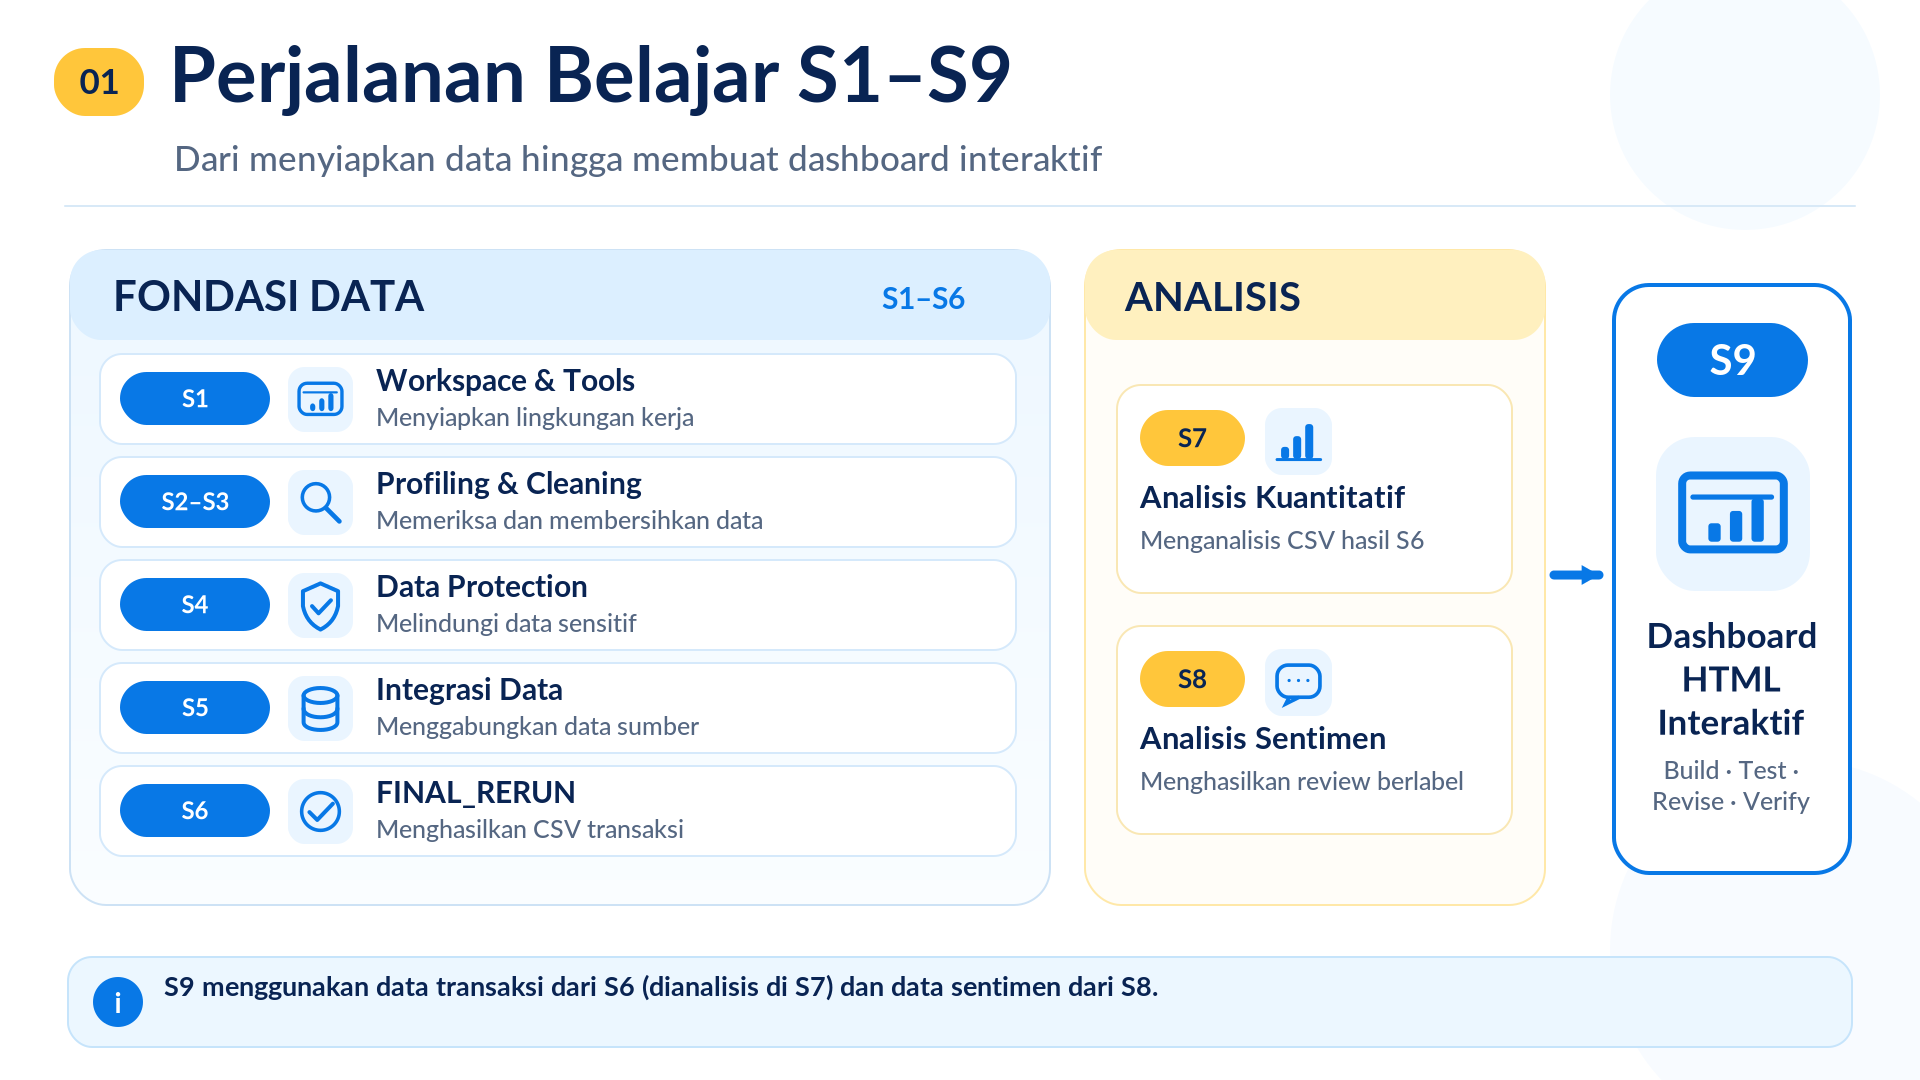

*Amati: S6 menghasilkan CSV transaksi, S7 menganalisisnya, S8 menghasilkan CSV review, dan S9 menyajikan kedua sumber dalam dashboard.*

## A2. Tugas kamu sebagai Data Analyst NusaMart

**Kasus bisnis:** Manajer ingin mengetahui jumlah pesanan, GMV, nilai tengah pesanan, tren bulanan, serta perbandingan komposisi sentimen antar kanal. Semua informasi harus mendukung satu keputusan: **kanal mana yang perlu ditinjau lebih lanjut?**

| Sumber | File resmi | Grain (makna satu baris) | Kegunaan |
|---|---|---|---|
| **Transaksi: output S6** | `nusamart_analysis_ready.csv` | **1 baris = 1 order** | Orders, GMV, Median Order Value, tren transaksi, performa kanal |
| **Sentimen: output S8** | `nusamart_reviews_labeled_s8.csv` | **1 baris = 1 review** | Positive %, Negative %, komposisi POSITIVE/NEUTRAL/NEGATIVE |

**Kontrak praktikum:** baseline 320 order dan 500 review. Jumlah tersebut digunakan sebagai **pemeriksaan**; jika berbeda, peserta harus meninjau penyebabnya bersama trainer, bukan menambah/menghapus record agar terlihat cocok.

**Temuan kualitas data yang pernah terlihat:** Dua CSV transaksi peserta yang sudah ditinjau mempunyai 20 `sales_channel` kosong. Ini **bukan 20 transaksi yang hilang**. Pada salinan kerja, kanal kosong menjadi **Tidak Diketahui**, tetapi CSV asli tidak diubah dan 20 order tetap dihitung.

**Contoh perbedaan antar peserta:** Label review hasil S8 dapat berbeda. Dashboard harus menghitung persentase berdasarkan **CSV peserta yang sedang digunakan**, bukan menyalin jawaban peserta lain.

> **Pertanyaan pemantik:** Apakah GMV tinggi membuktikan sentimen pelanggan positif? **Tidak.** Kedua ukuran berasal dari evidence layer yang berbeda. Hubungannya dalam dashboard bersifat **deskriptif**, bukan bukti sebab-akibat.


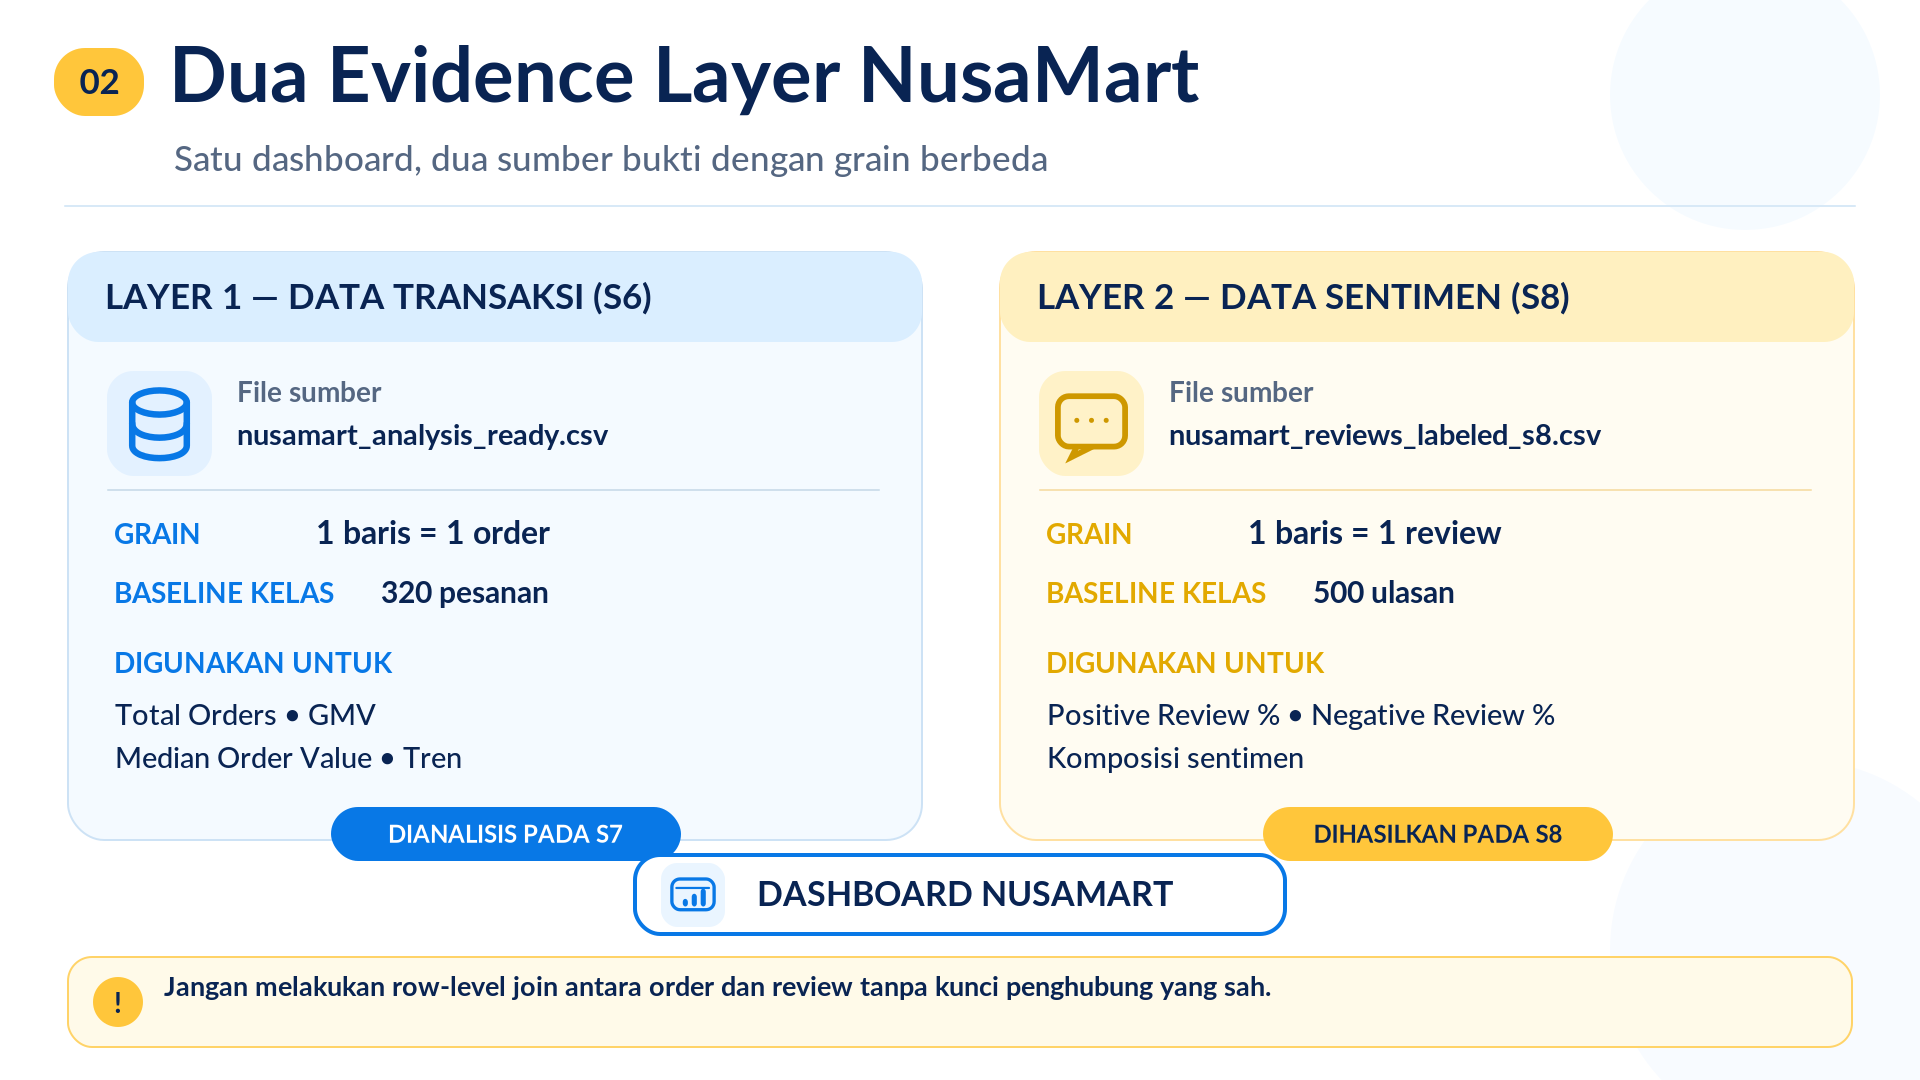

*Baca nama file dan grain sebelum melanjutkan. Kolom dengan nama sama bukan otomatis kunci yang mengizinkan row-level join.*

## A3. Persiapan file dan output

Simpan empat file berikut dalam **folder praktik yang sama** untuk memudahkan langkah berikutnya:

```text
practice/
└── sesi_09/
    ├── S9_NusaMart_Dashboard_Starter.ipynb
    ├── S9_NusaMart_Dashboard_Assertions.py
    ├── nusamart_analysis_ready.csv          ← dari FINAL_RERUN S6; digunakan juga di S7
    └── nusamart_reviews_labeled_s8.csv      ← dari hasil S8
```

- Gunakan CSV milikmu yang sudah dinyatakan final pada sesi sebelumnya. Jangan mengedit nama kolom atau mengubah data sumber.
- Jika unduhan mempunyai akhiran `(1)` atau `(2)`, pilih satu salinan yang benar kemudian gunakan **nama baku** di atas.
- Folder `outputs/sesi_09/` akan dibuat otomatis saat LANGKAH 01 dijalankan. File latihan, catatan review, dan snapshot hanya **bukti pendukung**, bukan tambahan output pengumpulan.

**Sebelum mulai:** Pastikan Jupyter Notebook/JupyterLab atau lingkungan Python Notebook telah dibuka dan empat file tersedia. LANGKAH 02 akan mengecek lokasinya secara otomatis.


# BAGIAN B · Memahami Python di Balik Dashboard

## B1. Python bekerja untuk apa?

**Python** adalah bahasa pemrograman yang digunakan di Notebook ini untuk membaca data, memeriksa kualitasnya, menghitung KPI awal, menyiapkan informasi grafik, dan **mengekspor HTML**. Kamu tidak diminta menulis ulang program, tetapi penting memahami apa yang dijalankan saat menekan **▶ Run**.

| Tahap | Teknologi | Apa yang dikerjakan? | Hasil yang akan kamu lihat |
|---|---|---|---|
| **Baca data** | Python + `pandas` | Membuka dua CSV sebagai tabel | Data transaksi dan ulasan siap diperiksa |
| **Periksa sumber** | Python | Validasi kolom, ID, tanggal, label, nilai dan missing | PASS / PASS WITH WARNING / STOP |
| **Hitung KPI awal** | Python + `pandas` | `nunique`, `sum`, `median`, proporsi review | Lima nilai default/dashboard snapshot |
| **Siapkan dashboard** | Python + Plotly | Mengemas data, aturan grafik, layout dan library grafik | File HTML latihan |
| **Berinteraksi di browser** | **JavaScript + Plotly** | Filter, Reset, hitung ulang KPI dan menggambar ulang grafik | Perubahan tampilan tanpa menjalankan Python lagi |
| **Buktikan angka** | Python Assertion Script | Hitung ulang lima KPI dari CSV asli secara independen | MATCH atau MISMATCH |

> **Perlu dibedakan:** Python membangun **file dashboard**; setelah HTML dibuka di Chrome/Edge, **JavaScript** yang menanggapi perubahan filter dan menggunakan Plotly untuk memperbarui grafik. Pengguna tidak perlu menjalankan Notebook ulang setiap kali memilih kanal.

**Analogi sederhana:** Python menyiapkan kendaraan dan muatannya; HTML adalah kendaraan yang dibuka pengguna; JavaScript/Plotly mengoperasikan kontrol dashboard selama digunakan.


## B2. Cara membaca Notebook dan potongan kode Python

| Bagian Notebook | Kegunaan | Tindakanmu |
|---|---|---|
| **Markdown Cell** | Menjelaskan kasus, materi dan instruksi | **Baca** terlebih dahulu |
| **Code Cell** | Berisi perintah Python | **Klik ▶ Run** secara berurutan |
| **Output Cell** | Menampilkan hasil program, tabel, lokasi file atau error | **Periksa** maknanya |
| **Variable** | Nama untuk menyimpan suatu nilai, misalnya `STATE` | Kenali apa yang disimpan |
| **Function** | Nama kumpulan langkah yang bisa dipanggil, misalnya `read_gate()` | Pahami tujuan fungsinya |

### Empat potongan kode yang perlu kamu kenali

**1. Membaca tabel dari CSV:**
```python
raw = pd.read_csv(path, low_memory=False)
```
`pd` adalah nama pendek untuk pandas. Kode membaca file menjadi DataFrame (tabel di memori).

**2. Menghitung jumlah order berbeda:**
```python
q['order_id'].nunique()
```
`nunique()` menghitung banyaknya ID order yang berbeda, bukan menjumlahkan nilai pesanan.

**3. Menghitung nilai tengah pesanan:**
```python
q['order_total'].median()
```
`median()` mengambil nilai tengah; **bukan** `mean()` (rata-rata).

**4. Membuat file HTML:**
```python
DRAFT_PATH = export_html(OUTPUT_DIR / 'dashboard_latihan_awal.html', PAYLOAD_AWAL)
```
Fungsi `export_html()` menyimpan dashboard dengan data dan script interaktif yang sudah disiapkan.

> Contoh di atas adalah **cuplikan kode untuk dipelajari**, bukan cell baru yang perlu kamu copy, edit, atau jalankan. Kode lengkap sudah disediakan di bawah masing-masing LANGKAH.

**Jika muncul error:** Baca pesan **STOP** atau error, jangan langsung mengganti kode. Jika kernel di-*restart*, nilai variabel yang disimpan di memori hilang, sehingga langkah sebelumnya harus dijalankan ulang secara berurutan.


## B3. Glosarium cepat: 15 istilah paling penting

| Istilah | Arti yang dipakai di S9 |
|---|---|
| **Python** | Bahasa untuk membaca sumber, memvalidasi data dan menyiapkan file dashboard. |
| **Notebook / `.ipynb`** | Dokumen gabungan materi, cell kode dan hasil eksekusinya. |
| **Library** | Kumpulan fungsi siap pakai, contohnya `pandas` dan Plotly. |
| **DataFrame** | Bentuk tabel yang dikelola pandas di memori. |
| **CSV** | Berkas teks berisi data tabel. |
| **Grain** | Arti satu baris: satu order atau satu review. |
| **KPI** | Angka utama untuk memantau performa. |
| **GMV** | Jumlah nilai transaksi `order_total`; bukan otomatis keuntungan. |
| **Median** | Nilai tengah setelah data diurutkan. |
| **Filter** | Pembatas cakupan berdasarkan kanal, wilayah atau tanggal. |
| **Plotly** | Library grafik interaktif yang disertakan di HTML. |
| **JavaScript** | Program di browser yang menggerakkan filter/Reset dan pembaruan tampilan. |
| **HTML self-contained** | HTML dengan library yang dibutuhkan disertakan di file, tanpa CDN. |
| **Assertion** | Pemeriksaan angka dashboard dibanding kalkulasi independen. |
| **PASS / WARNING / STOP** | Lanjut / lanjut dengan catatan / hentikan untuk pemeriksaan. |

**Glosarium lengkap** terdapat pada bagian referensi di akhir Notebook, sehingga tidak harus dihafalkan sebelum praktik.


# BAGIAN C · Merancang Dashboard yang Tepat

## C1. Dari Business Question menuju lima KPI

**Pertanyaan bisnis:** *Bagaimana performa transaksi dan sentimen berbeda antar kanal?*

| KPI wajib | Aturan hitung **pada cakupan filter** | Makna untuk manajer |
|---|---|---|
| **Total Orders** | Banyak `order_id` yang unik | Volume transaksi |
| **Total GMV** | `SUM(order_total)` | Nilai transaksi (bukan laba) |
| **Median Order Value** | `MEDIAN(order_total)` | Nilai pesanan tengah |
| **Positive Review %** | `POSITIVE ÷ seluruh review yang terfilter × 100%` | Proporsi ulasan positif |
| **Negative Review %** | `NEGATIVE ÷ seluruh review yang terfilter × 100%` | Proporsi ulasan negatif |

**Median vs mean — contoh ilustratif:** Nominal Rp50.000, Rp75.000, Rp100.000, Rp125.000, dan Rp650.000 mempunyai **median Rp100.000**, tetapi **mean Rp200.000**. Angka yang sangat besar memengaruhi mean lebih kuat. Di S9 KPI yang diminta adalah **median**, bukan mean.

**N/A bukan 0%:** Jika hasil filter tidak mempunyai **review sama sekali**, persentase sentimen **tidak bisa dihitung** dan harus tampil N/A. Jika ada review tetapi tidak ada satu pun berlabel POSITIVE, Positive Review % sah bernilai 0%.

**Pertanyaan cepat:** Apakah “Total GMV tinggi” otomatis berarti “Negative Review % rendah”? **Tidak**, karena keduanya indikator yang berbeda dan tidak menjelaskan sebab-akibat secara langsung.


## C2. Mengapa memilih grafik ini?

Sebelum memilih bentuk grafik, tentukan **apa yang perlu dilihat**: angka ringkas, perbandingan kategori, perubahan waktu, atau komposisi kelompok.

| Komponen dashboard | Pertanyaan | Bentuk aktual di Starter | Alasan pemilihan |
|---|---|---|---|
| **5 KPI Cards** | Berapa kondisi keseluruhan? | Lima kartu angka | Cepat dibaca sebelum menganalisis grafik |
| **Grafik 1 — Performa per Kanal** | Kanal mana lebih tinggi? | **Batang order + garis GMV**, dua sumbu nilai | Membandingkan kategori kanal dan menampilkan dua satuan berbeda |
| **Grafik 2 — Tren Transaksi** | Apa berubah dari bulan ke bulan? | **Dua garis**, order dan GMV, dua sumbu nilai | Bulan memiliki urutan sehingga pola naik/turun terlihat |
| **Grafik 3 — Komposisi Sentimen** | Berapa persentase positive/neutral/negative per kanal? | **Stacked bar** tiga kategori sentimen | Memudahkan perbandingan proporsi dalam setiap kanal |
| **Filter + Reset** | Bagaimana jika ingin fokus ke kanal/wilayah/periode? | Dropdown, dua input tanggal, Reset | Menelusuri informasi tanpa membuat banyak dashboard |

### Cara membaca grafik aktual

**Grafik 1 — Batang dan garis:**
- **Sumbu-X:** Sales Channel. **Sumbu-Y kiri:** Jumlah order (**batang biru**). **Sumbu-Y kanan:** GMV Rupiah (**garis kuning**).
- Dua sumbu berbeda **tidak boleh** dibandingkan dengan tinggi visual saja; baca label dan tooltip per seri.
- Kanal `Tidak Diketahui` tetap ditampilkan jika terdapat order tanpa kanal.

**Grafik 2 — Dua garis tren bulanan:**
- **Sumbu-X:** Bulan dari `order_date`. **Y kiri:** order, **Y kanan:** GMV Rupiah.
- Gunakan untuk melihat perubahan menurut waktu, **bukan** menyimpulkan bahwa satu garis menyebabkan garis lain naik.

**Grafik 3 — Stacked bar persentase:**
- Setiap kanal berisi proporsi review POSITIVE, NEUTRAL, dan NEGATIVE dari total review **di kanal itu**.
- Bila kanal tidak mempunyai review, tampilkan **N/A** dan keterangan, jangan mengisi semua segmen dengan 0%.

**Mengapa bukan pie chart untuk tren?** Karena pie chart tidak menunjukkan urutan waktu yang dibutuhkan untuk membaca kenaikan dan penurunan tiap bulan.


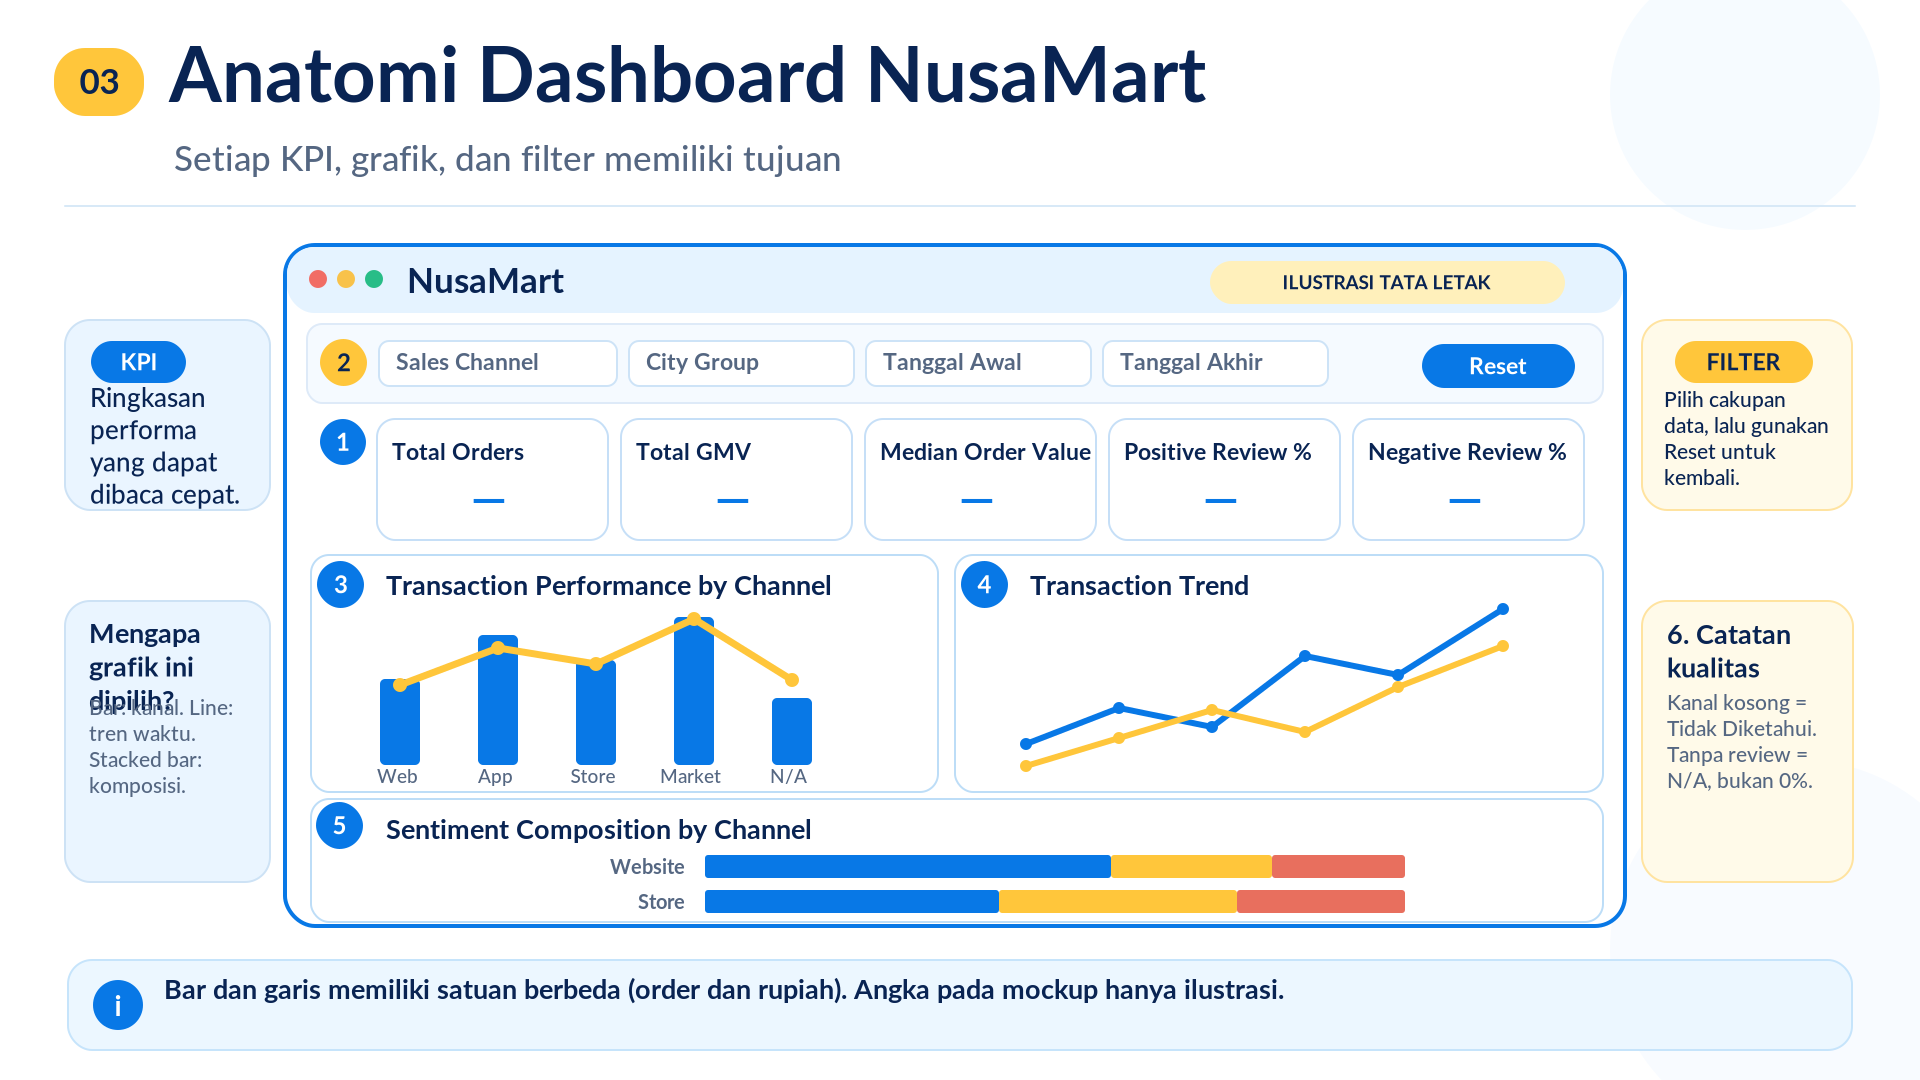

*Visual adalah peta tata letak; angka KPI memakai tanda — agar tidak disalahpahami sebagai hasil aktual. Di praktik, seluruh nilai mengikuti dua CSV yang kamu gunakan.*

## C3. Bagaimana filter memengaruhi dua evidence layer?

**Sales Channel** dan **City Group** membatasi kategori. **Periode awal/akhir** membatasi `order_date` pada transaksi dan `review_date` pada ulasan **secara terpisah**. Tombol **Reset** mengembalikan seluruh filter pada kondisi awal.

| Yang dipilih pengguna | Yang berubah pada dashboard |
|---|---|
| Kanal = Store | KPI transaksi dari order Store; KPI sentimen dari review Store |
| Kanal = Store + City Group tertentu | Kedua dataset menggunakan kombinasi kanal dan wilayah itu secara terpisah |
| Tanggal awal dan akhir | Hanya record sesuai tanggal masing-masing sumber yang dihitung |
| Reset | Kembali ke kanal, wilayah dan periode keseluruhan |
| Tidak ada review pada filter | Total Orders/GMV dapat tetap tampil, sedangkan persentase sentimen = **N/A** |

**Kasus kualitas data:** Jika `sales_channel` kosong, Source Gate mencatatnya dan memakai **Tidak Diketahui** hanya pada data kerja. Dashboard tetap menghitung record valid tersebut pada Total Orders/GMV, tanpa mengarang asal kanalnya.

**Satu hal yang tidak boleh dilakukan:** Menganggap hasil dari filter yang sama berarti order dan review berhubungan secara individual. Kita sedang **membandingkan ringkasan dua sumber**, bukan membuat hubungan satu-per-satu.


# BAGIAN D · AI Agent, Prompt A/B, serta TEST dan VERIFY

## D1. Di mana peran AI Agent dan Antigravity?

**Data Analyst menentukan** pertanyaan bisnis, asal file, definisi KPI, bentuk grafik, aturan kualitas data, dan syarat penerimaan. **AI Agent dapat membantu** menyusun serta merevisi kode, tetapi tidak menggantikan tugas Analyst dalam memeriksa hasil.

- **Jalur praktik S9:** Notebook telah berisi kode Python dan JavaScript siap Run. Kamu cukup menjalankan, mengamati hasil dan melakukan uji browser.
- **Jalur demonstrasi trainer:** Antigravity digunakan untuk menunjukkan bagaimana Prompt B mengarahkan revisi terfokus.
- **Jalur Capstone:** Kamu menerapkan pola pikir brief, batasan dan verifikasi pada data dan tugas yang berbeda, tanpa bergantung pada angka dan KPI NusaMart.

**Perbedaan Chat AI dan Agent:** Chat AI dapat menjelaskan ide atau kode. Agent pada lingkungan yang diizinkan dapat membantu bekerja lintas file dan tools. Dalam keduanya, perubahan serta kesimpulan tetap perlu ditinjau manusia.


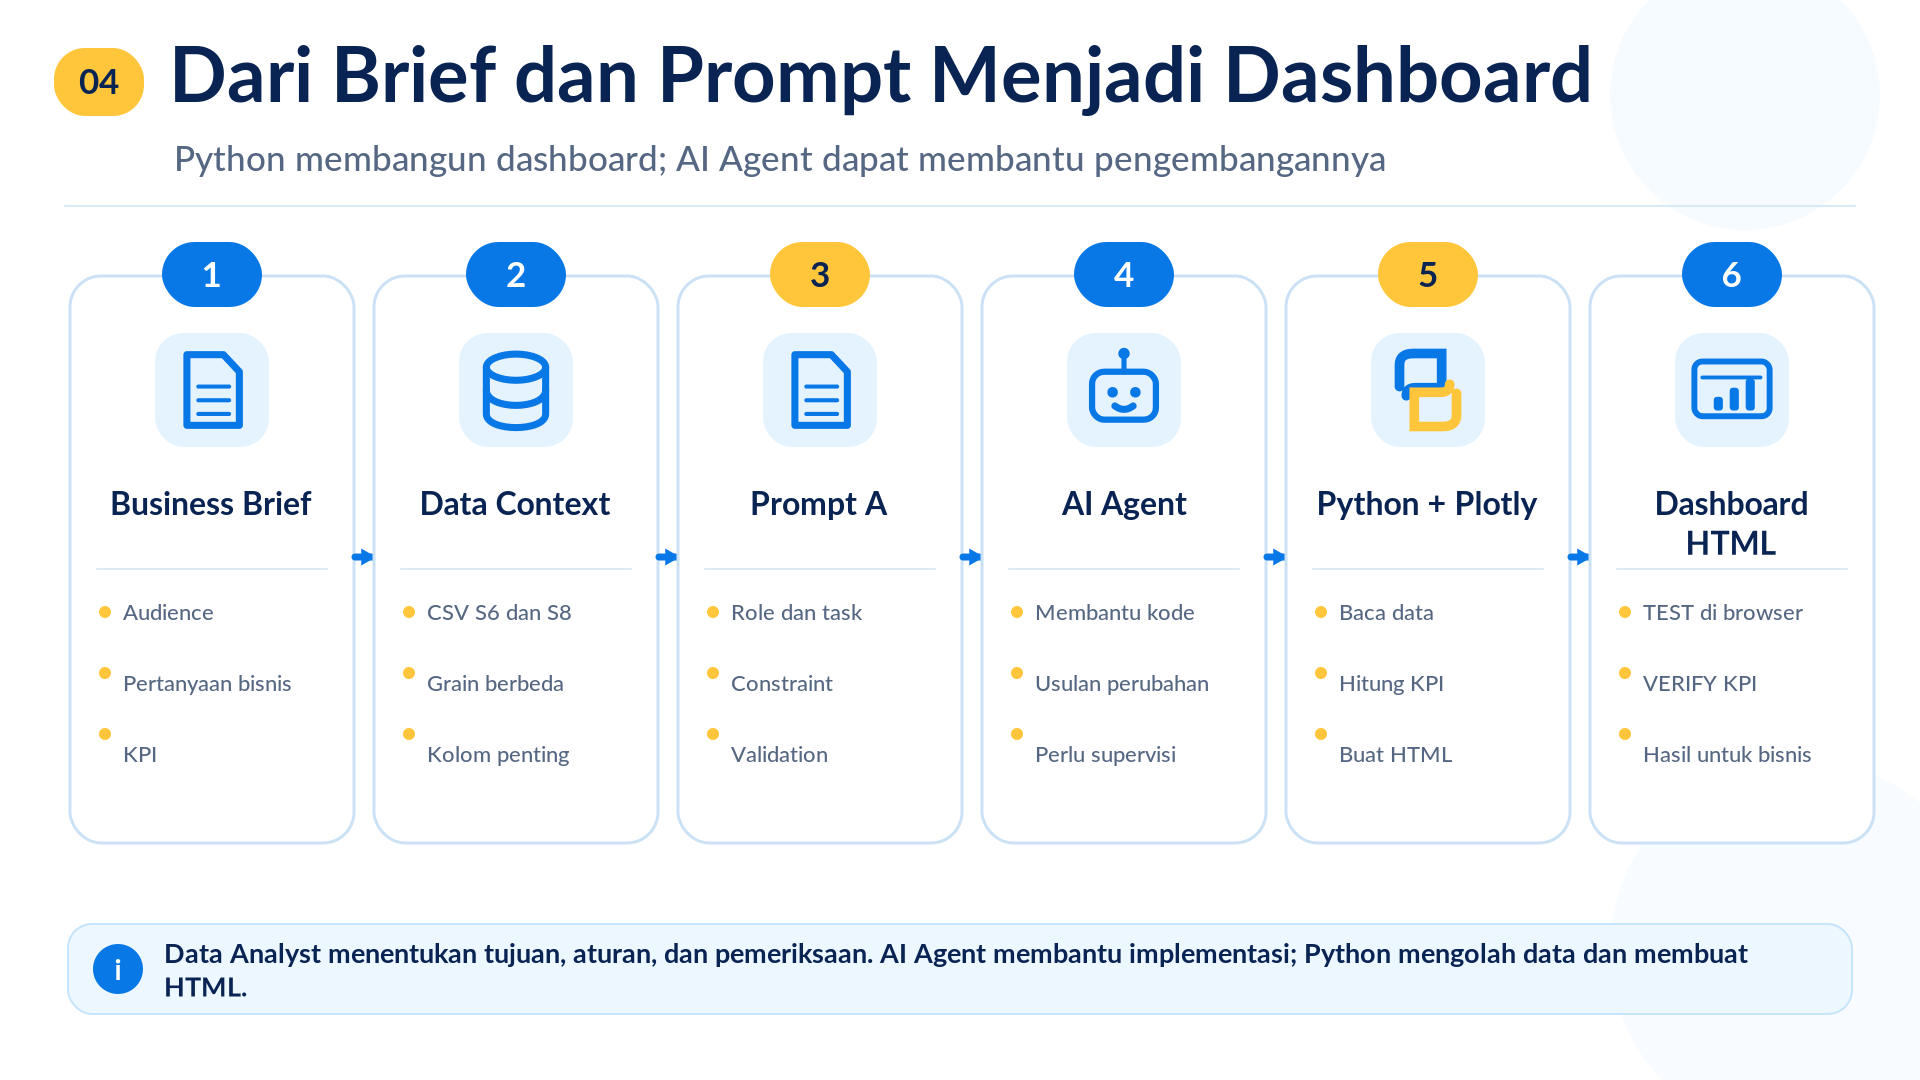

*Amati bagian “Python + Plotly”: ini adalah mesin pengolah dan pembuat HTML yang kamu jalankan pada Starter. AI Agent adalah bantuan implementasi, bukan syarat untuk menyelesaikan S9.*

## D2. Prompt A — Membangun dashboard dari awal (dipelajari, **tidak dieksekusi**)

Di S9, peserta memakai template kode siap Run. Namun, pada Capstone, kamu perlu mampu menjelaskan masalah kepada AI Agent tanpa bergantung pada Starter. Karena itu, **pelajari Prompt A, bukan mengirimkannya ke Antigravity pribadi**.

**Anatomi brief Agent:** ROLE → BUSINESS QUESTION → DATA PROVENANCE & GRAIN → KPI RULES → VISUAL/FILTER → DATA QUALITY → OUTPUT/VERIFY → ACCEPTANCE CHECK.

> **PROMPT A — BUILT FROM SCRATCH**
>
> Berperan sebagai AI Agent pengembang dashboard data yang dapat menjelaskan keputusan teknisnya. Saya adalah Data Analyst NusaMart dan harus membantu Commercial / Business Performance Manager menjawab: *Bagaimana performa transaksi dan sentimen pelanggan berbeda antar sales channel, dan kanal mana yang perlu mendapat perhatian?*
>
> **Sumber 1:** `nusamart_analysis_ready.csv` adalah output **FINAL_RERUN S6**, satu baris per order, kemudian dianalisis di **S7**. Kolom penting: `order_id`, `order_date`, `order_total`, `sales_channel`, `city_group`.
>
> **Sumber 2:** `nusamart_reviews_labeled_s8.csv` adalah output **S8**, satu baris per review, dengan `review_id`, `review_date`, `sentiment_label`, `sales_channel`, `city_group`. Label valid: POSITIVE, NEUTRAL, NEGATIVE. Label Agent S8 bukan kebenaran mutlak seluruh review; audit manual hanya terbatas.
>
> **Aturan:** Jangan menggabungkan setiap order dengan setiap review karena tidak ada kunci hubungan satu-per-satu yang sah. Filter kedua dataset **secara terpisah** melalui `sales_channel`, `city_group`, dan periode. Tanggal transaksi dan review masing-masing memakai kolom tanggal miliknya.
>
> **Lima KPI wajib:** `nunique(order_id)`, `sum(order_total)`, `median(order_total)`, jumlah POSITIVE/total review, jumlah NEGATIVE/total review. Tampilkan N/A jika jumlah review pada filter adalah nol.
>
> **Tiga grafik:** (1) jumlah order dan GMV per sales channel, dengan satuan jelas; (2) tren order dan GMV menurut tanggal/periode; (3) komposisi label sentimen per sales channel. Sediakan filter sales channel, city group, periode, dan Reset. Setiap filter mengubah seluruh KPI dan grafik.
>
> **Kualitas data:** Periksa baseline kelas 320 order dan 500 review, ID unik, tanggal valid, nilai transaksi angka tidak negatif, kategori label valid. `sales_channel` yang kosong **boleh menjadi WARNING** dan harus ditampilkan sebagai `Tidak Diketahui` pada salinan data kerja, bukan dihapus atau ditebak. Pertahankan sumber asli. Kanal tanpa review mempunyai metrik sentimen N/A, bukan 0%.
>
> **Hasil teknis:** Buat dashboard Plotly dalam **satu HTML self-contained** yang dapat dibuka lokal, dengan lima KPI, tiga grafik, filter nyata, tooltip, legend, dan catatan kualitas data. Sertakan lima nilai KPI default yang benar-benar dirender sebagai snapshot terpisah untuk pemeriksaan independen. Jangan menyatakan PASS tanpa menguji.
>
> **Batasan:** Jangan mengarang temuan, jangan mengganti rumus median dengan mean, jangan mengunci jawaban KPI peserta tertentu. Berikan panduan menjalankan, pengujian filter/Reset, dan daftar potensi kegagalan. Kode perlu direview dan diverifikasi oleh manusia.

**Latihan membaca (tanpa menulis kode):** Temukan di atas (1) asal CSV transaksi, (2) lima rumus KPI, (3) aturan missing channel, (4) ketentuan filter, dan (5) alasan assertion terpisah. **Adaptasi untuk Capstone:** jumlah record, struktur file, KPI, dan pertanyaan bisnis wajib mengikuti dataset Capstone yang sebenarnya, bukan disalin mentah dari NusaMart.


## D3. Prompt B — Meminta satu perbaikan yang terarah

Prompt B digunakan **setelah** melihat hasil functional review. Struktur instruksi yang baik:

1. **Konteks:** Dashboard NusaMart memakai sumber transaksi S6 dan ulasan S8.
2. **Temuan:** Sebutkan perilaku atau teks yang memang diamati, misalnya judul belum menunjukkan satuan.
3. **Permintaan:** Minta **satu** revisi yang spesifik, misalnya judul “Komposisi Ulasan per Kanal (%)”.
4. **Batasan:** Jangan ubah CSV asli, rumus KPI, filter, atau logika data kosong.
5. **Retest:** Jelaskan cara membuktikan bahwa perbaikan terjadi dan fungsi lain tetap berjalan.

**Contoh:** “Judul grafik sentimen belum menjelaskan nilai berupa persentase review. Tolong perjelas **judul saja**; jangan ubah data, KPI, atau filter. Setelahnya cek kembali judul, grafik, tooltip dan Reset.”

Pada LANGKAH 07, Notebook **membuat Prompt B otomatis** setelah kamu memilih satu dari empat opsi: judul, legend, tooltip, atau penjelasan filter. Kamu **tidak harus mengirimnya** ke Antigravity; trainer yang mendemonstrasikan bila diperlukan.


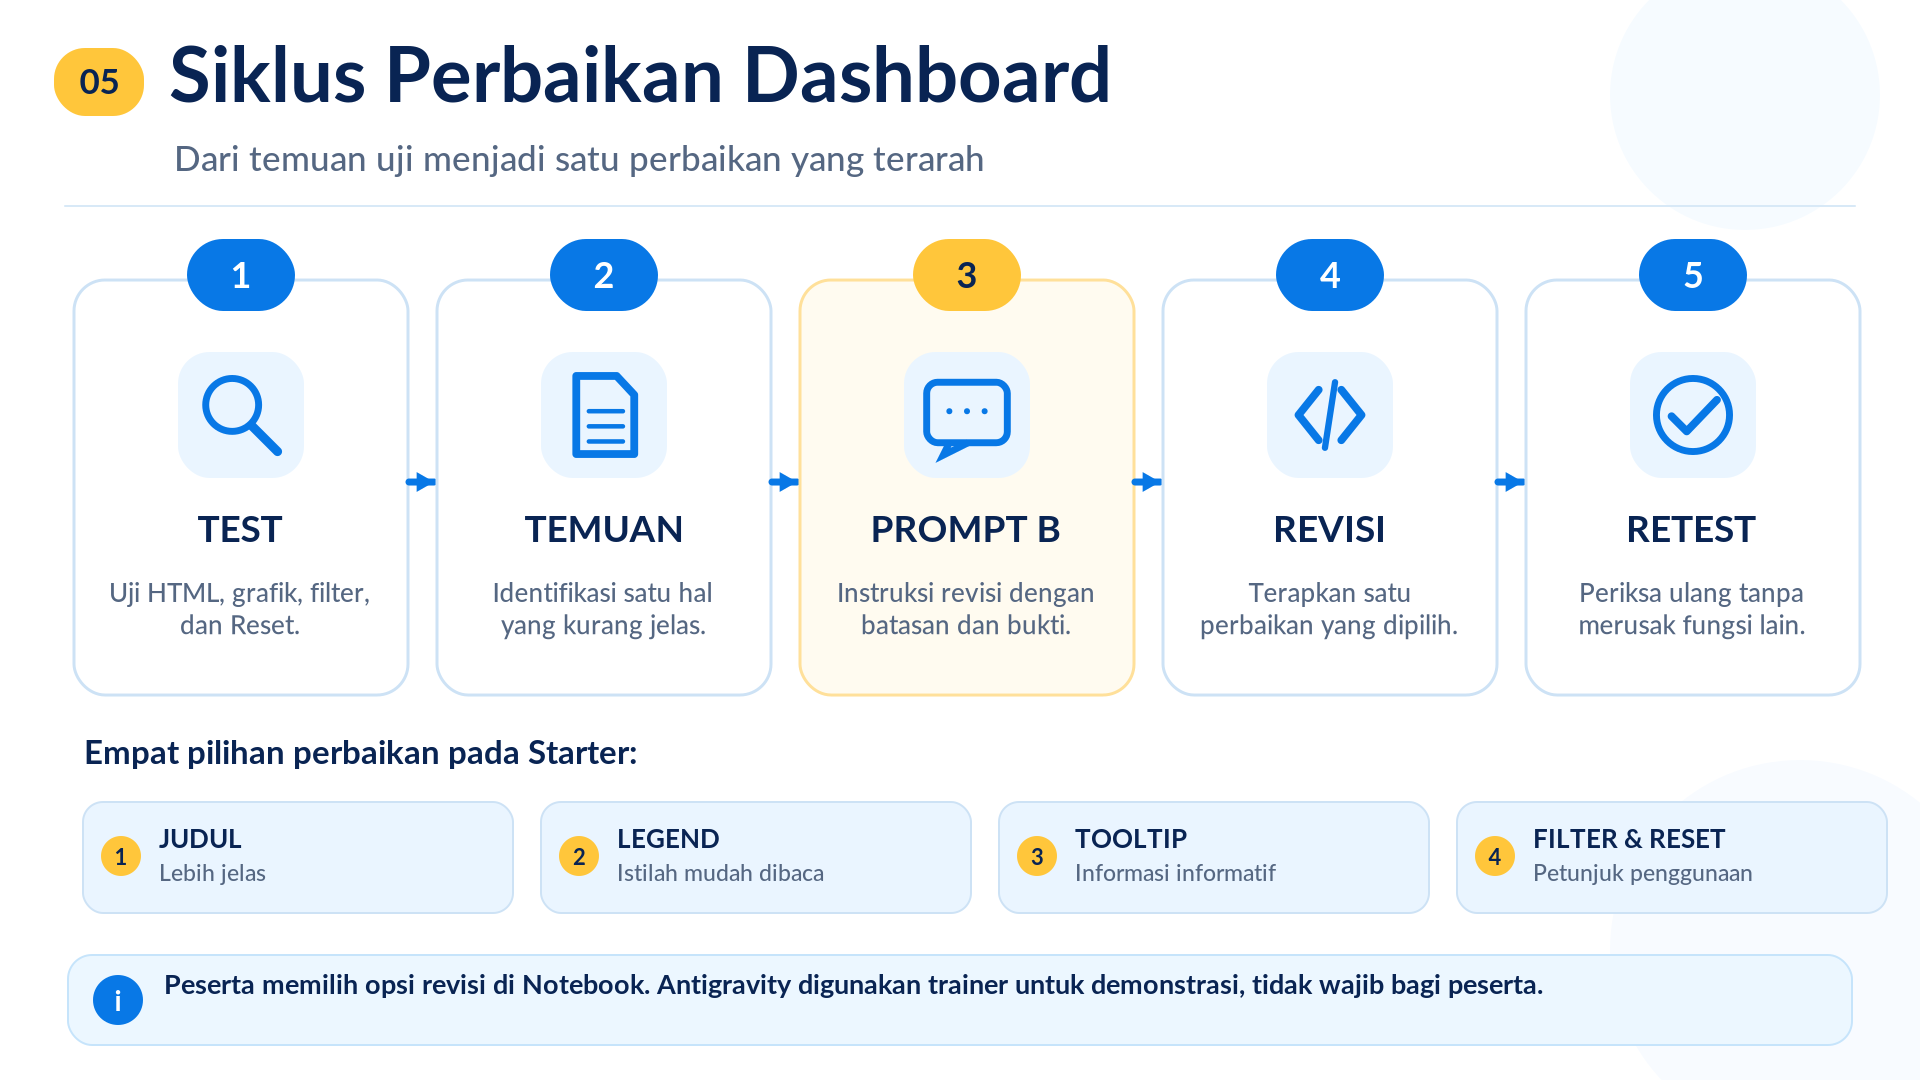

*Hubungkan visual ini dengan LANGKAH 06–08: uji nyata → satu temuan → Prompt B → perbaikan dari template → uji ulang.*

## D4. TEST ≠ VERIFY — Dua pemeriksaan yang tidak boleh tertukar

| **TEST (Browser)** | **VERIFY (Assertion Python)** |
|---|---|
| HTML terbuka secara lokal | Lima KPI default dihitung ulang dari CSV asli |
| Lima kartu dan tiga grafik terlihat | Definisi `nunique`, `sum`, `median`, serta penyebut sentimen diperiksa |
| Filter kanal, wilayah, tanggal dan Reset bekerja | Snapshot nilai kartu awal dibandingkan dengan nilai independen |
| Judul, legend dan tooltip terbaca | Hasilnya **MATCH** atau **MISMATCH** |

**Aturan penting:** `FUNCTIONAL REVIEW: RECORDED` adalah hasil **jawaban manual peserta**, bukan browser otomatis diverifikasi Python. `5/5 MATCH` berarti **lima KPI cakupan default** cocok; ini **tidak otomatis** membuktikan semua kombinasi filter berfungsi atau setiap label S8 benar secara substantif.

> **Contoh risiko:** HTML dapat terbuka dan kartu median terisi, tetapi angkanya salah jika kode memakai `mean()` ketika brief meminta `median()`. Karena itu kita memerlukan VERIFY.


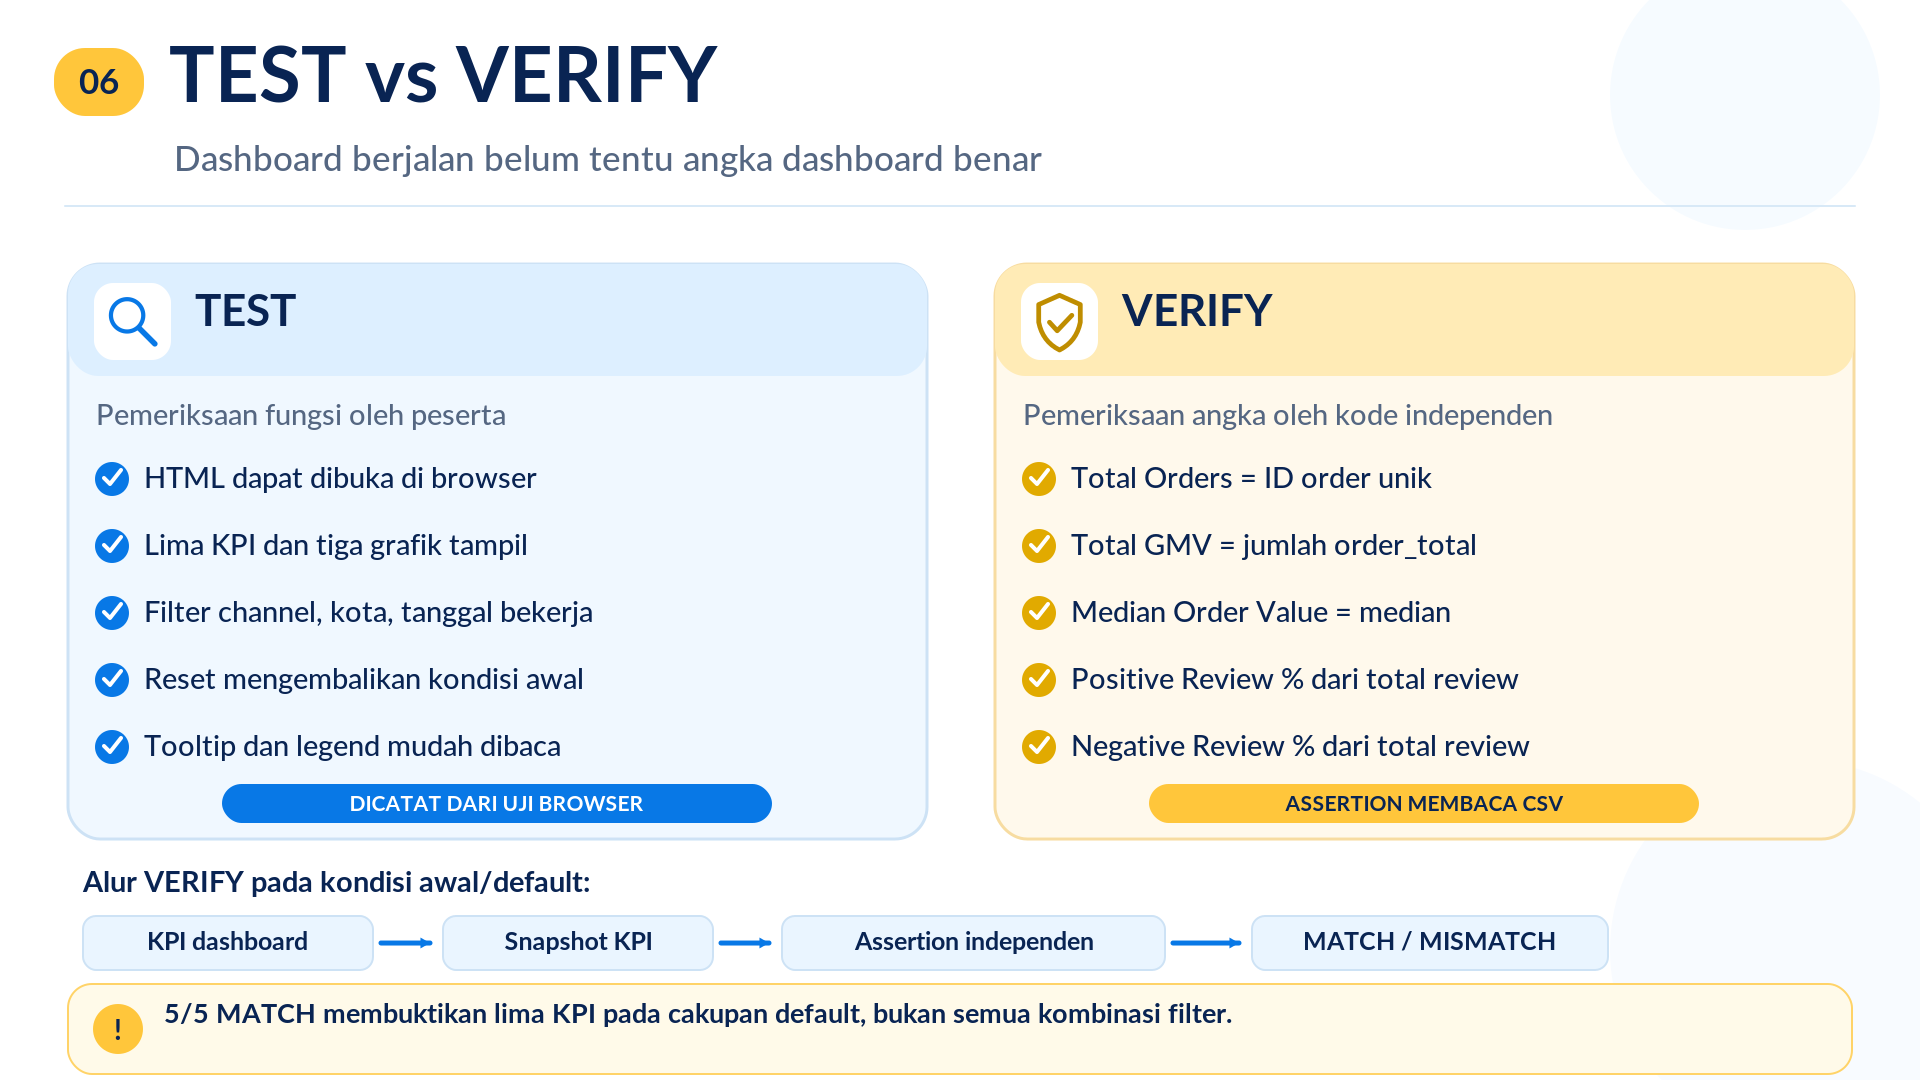

*Perhatikan dua jalur bukti: browser diperiksa oleh pengguna, sedangkan angka KPI default dibandingkan dengan perhitungan Assertion Script terpisah.*

# BAGIAN E · Praktik Terpandu 90 Menit

## Peta 11 langkah dan durasinya

| Waktu | Langkah | Hasil utama |
|---|---|---|
| 00–03′ | **01** Nyalakan mesin | `MESIN STARTER: SIAP` |
| 03–10′ | **02** Temukan file | `WORKSPACE CHECK: PASS` |
| 10–15′ | **03** Source Gate | PASS / PASS WITH WARNING / STOP |
| 15–20′ | **04** Kunci desain | `DESIGN SPEC: READY` |
| 20–40′ | **05** Bangun dashboard | `dashboard_latihan_awal.html` |
| 40–55′ | **06** Functional review | `functional_review.json` |
| 55–62′ | **07** Prompt B | `prompt_revisi_dashboard.txt` |
| 62–70′ | **08** Perbaikan + Retest | `dashboard_latihan_perbaikan.html` |
| 70–82′ | **09** Assertion | `5/5 MATCH` dan `assertion_results.csv` |
| 82–86′ | **10** HTML final | `S9_NusaMart_Dashboard_Final.html` |
| 86–90′ | **11** Final Check | `FINAL CHECK: LOLOS` bila seluruh syarat terpenuhi |

**Cara menjalankan:** Klik **▶ Run** pada **satu code cell** setelah penjelasan LANGKAH yang bersangkutan. **Tunggu outputnya**, baca bagian “Arti hasil”, kemudian lanjut. Jangan menjalankan dari LANGKAH 05 sebelum LANGKAH 01–04 lulus. Jika terjadi STOP, perbaiki penyebabnya bersama trainer.

**Catatan:** Potongan kode pada materi di atas hanya untuk dipelajari. **Sebelas code cell berikut merupakan praktik sesungguhnya.**


## LANGKAH 01 · Nyalakan Mesin Starter ⏱ 3 menit

**Kasus.** Sebelum membuat dashboard, perangkat Python perlu mengetahui library dan folder tempat hasil disimpan.

| Pertanyaan | Penjelasan |
|---|---|
| **Kita akan apa?** | Menyiapkan lingkungan kerja, mengimpor library, dan membuat folder `outputs/sesi_09/`. |
| **Untuk apa?** | Agar langkah berikutnya dapat membaca file, membuat grafik, dan menyimpan HTML. |
| **Konsep Python** | `import` memanggil library; `Path.cwd()` menunjukkan folder aktif; `mkdir()` membuat folder bila belum ada. |

**Di balik kode — baca cuplikan ini, jangan perlu mengetiknya:**
```python
S9_ROOT = Path.cwd().resolve()
OUTPUT_DIR = S9_ROOT / 'outputs' / 'sesi_09'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
STATE = {'engine': True}
```
`STATE` adalah penanda bahwa mesin telah disiapkan; langkah berikutnya akan memeriksa penanda tersebut.

**Yang kamu lakukan:** Buka Notebook, temukan code cell tepat di bawah bagian ini, klik **▶ Run** sekali dan tunggu sampai hasil muncul.

**Hasil yang dihasilkan:** Versi Python/pandas/Plotly dan dua lokasi folder. **Cara membaca:** `MESIN STARTER: SIAP` artinya lingkungan dasar siap, **belum** berarti data ditemukan atau tervalidasi.

**Checkpoint/STOP:** Lanjut jika `MESIN STARTER: SIAP`. Jika muncul error library, minta bantuan trainer; jangan meloncat ke LANGKAH 02 tanpa menyelesaikannya.


In [1]:
%pip install plotly

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\lucih\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import sys, json, re, importlib.util
from datetime import datetime
from html import escape
import pandas as pd
import numpy as np
import plotly
from plotly.offline import get_plotlyjs
from IPython.display import display

S9_ROOT = Path.cwd().resolve()
OUTPUT_DIR = S9_ROOT / 'outputs' / 'sesi_09'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
STATE={'engine': True}
print('MESIN STARTER: SIAP')
print('Python:',sys.version.split()[0], '| pandas:',pd.__version__, '| plotly:',plotly.__version__)
print('Folder kerja:',S9_ROOT)
print('Folder hasil:',OUTPUT_DIR)

MESIN STARTER: SIAP
Python: 3.13.14 | pandas: 3.0.6 | plotly: 7.1.0
Folder kerja: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09
Folder hasil: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\outputs\sesi_09


## LANGKAH 02 · Temukan Sumber Data ⏱ 7 menit

**Kasus.** File peserta bisa tersimpan di folder berbeda atau terunduh berkali-kali. Dashboard akan salah jika membaca file bukan final.

| Pertanyaan | Penjelasan |
|---|---|
| **Kita akan apa?** | Mencari dua CSV dan satu Assertion Script berdasarkan nama baku. |
| **Untuk apa?** | Memastikan lokasi input sudah jelas sebelum datanya diproses. |
| **Konsep Python** | `Path` menunjuk lokasi file; `.is_file()` memeriksa keberadaan file; fungsi `locate_file()` mendeteksi file yang hilang/ganda. |

**Di balik kode:**
```python
FILES = {'transactions':'nusamart_analysis_ready.csv',
         'reviews':'nusamart_reviews_labeled_s8.csv',
         'assertions':'S9_NusaMart_Dashboard_Assertions.py'}
PATHS = {key:locate_file(value) for key,value in FILES.items()}
```
Artinya: setiap input dicari, lalu lokasi sebenarnya disimpan agar langkah berikutnya menggunakan file yang sama.

**Yang kamu lakukan:** Cek empat file di Explorer → kembali ke LANGKAH 02 → klik **▶ Run** → baca ketiga lokasi sumber.

**Hasil yang dihasilkan:** Daftar path transaksi, reviews dan assertions; `WORKSPACE CHECK: PASS`.

**Cara membaca:** PASS pada tahap ini **hanya membuktikan file ada**. Pemeriksaan jumlah baris dan isi berlangsung pada LANGKAH 03.

**Checkpoint/STOP:** Jika file tidak ditemukan atau terdeteksi salinan ganda, rapikan folder dan nama baku, kemudian jalankan ulang. Jangan membuat file kosong sebagai pengganti.


In [3]:
assert STATE.get('engine'), 'STOP: jalankan LANGKAH 01.'
FILES={'transactions':'nusamart_analysis_ready.csv',
       'reviews':'nusamart_reviews_labeled_s8.csv',
       'assertions':'S9_NusaMart_Dashboard_Assertions.py'}
def locate_file(name):
    preferred=[S9_ROOT/name, S9_ROOT/'data'/name,
               S9_ROOT/'outputs'/'sesi_06'/name,
               S9_ROOT/'outputs'/'sesi_08'/name,
               S9_ROOT/'practice'/'sesi_09'/name]
    existing=[p.resolve() for p in preferred if p.is_file()]
    if len(existing)>1:
        raise RuntimeError(f'STOP: {name} berada di beberapa lokasi. Sisakan satu salinan final di folder Notebook.')
    if existing:return existing[0]
    matches=[p.resolve() for p in S9_ROOT.rglob(name) if p.is_file()]
    if len(matches)==1:return matches[0]
    if len(matches)>1:raise RuntimeError(f'STOP: beberapa file {name} ditemukan, pilih satu di folder Notebook.')
    raise FileNotFoundError(f'STOP: file {name} belum ditemukan. Ambil dari sesi asal lalu ulangi.')
STATE['workspace']=False
PATHS={key:locate_file(value) for key,value in FILES.items()}
for key,path in PATHS.items():print(f'{key:>12}: {path}')
STATE['workspace']=True
print('WORKSPACE CHECK: PASS')

transactions: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\nusamart_analysis_ready.csv
     reviews: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\nusamart_reviews_labeled_s8.csv
  assertions: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\S9_NusaMart_Dashboard_Assertions.py
WORKSPACE CHECK: PASS


## LANGKAH 03 · Periksa Sumber dan Kualitas Data ⏱ 5 menit

**Kasus.** Data transaksi mungkin mempunyai `sales_channel` kosong. Kita harus membedakan keterbatasan yang boleh dijelaskan dari kesalahan yang menghentikan analisis.

| Pertanyaan | Penjelasan |
|---|---|
| **Kita akan apa?** | Membaca dua CSV, memeriksa baseline 320 order/500 review, kolom wajib, ID unik, tanggal, nilai order, label sentimen dan missing values. |
| **Untuk apa?** | Mencegah dashboard dibuat dari data yang salah atau tidak lengkap secara fatal. |
| **Konsep Python** | `pd.read_csv()` membuka CSV; `nunique()` menghitung ID berbeda; `pd.to_datetime()` memeriksa tanggal; `isna()` mengenali nilai kosong. |

**Di balik kode:**
```python
raw = pd.read_csv(path, low_memory=False)
df = raw.copy()                 # salinan kerja, bukan mengedit CSV sumber
# Pada salinan kerja, kanal/wilayah kosong diberi 'Tidak Diketahui'
```
Fungsi `read_gate()` menerapkan seluruh aturan validasi pada setiap dataset dan menghentikan proses jika ada pelanggaran inti.

**Yang kamu lakukan:** Klik **▶ Run**, lalu baca tabel audit dua baris: **Transaksi S6** dan **Sentimen S8**. Perhatikan jumlah baris, ID unik, dan jumlah kanal/wilayah yang kosong.

**Hasil yang dihasilkan:** Tabel audit (`AUDIT`), data kerja (`quant`, `reviews`) dan status `SOURCE GATE: PASS` atau `PASS WITH WARNING`. CSV asli tetap tidak ditimpa.

**Cara membaca:**
- **PASS:** seluruh pemeriksaan terpenuhi.
- **PASS WITH WARNING:** ada nilai dimensi kosong yang diberi kategori **Tidak Diketahui** pada data kerja; misalnya 20 order tanpa kanal pada contoh peserta.
- **STOP:** ID duplikat, baseline tidak sesuai, kolom wajib hilang, tanggal/order_total tidak valid, atau label sentimen asing.

**Checkpoint/STOP:** Lanjut hanya jika Source Gate PASS/WARNING. Jika STOP, konsultasikan data/asal file dengan trainer. **Jangan menghapus order atau menebak channel** untuk mengejar PASS.


In [4]:
assert STATE.get('workspace'), 'STOP: selesaikan LANGKAH 02.'
STATE['source']=False
Q_REQUIRED={'order_id','order_date','order_total','sales_channel','city_group'}
R_REQUIRED={'review_id','review_date','sentiment_label','sales_channel','city_group'}
ALLOWED_LABELS={'POSITIVE','NEUTRAL','NEGATIVE'}
UNKNOWN='Tidak Diketahui'

def read_gate(path,mode):
    raw=pd.read_csv(path,low_memory=False)
    required,expected,id_col,date_col=(Q_REQUIRED,320,'order_id','order_date') if mode=='orders' else (R_REQUIRED,500,'review_id','review_date')
    absent=sorted(required-set(raw.columns))
    if absent:raise ValueError(f'STOP {mode}: kolom wajib hilang: {absent}')
    if len(raw)!=expected:raise ValueError(f'STOP {mode}: jumlah baris {len(raw)} bukan baseline {expected}. Minta peninjauan trainer.')
    ids=raw[id_col].astype('string').str.strip()
    if ids.isna().any() or ids.eq('').any() or ids.nunique()!=expected:
        raise ValueError(f'STOP {mode}: {id_col} kosong atau tidak unik.')
    df=raw.copy()
    df[date_col]=pd.to_datetime(df[date_col],errors='coerce')
    if df[date_col].isna().any():raise ValueError(f'STOP {mode}: tanggal {date_col} tidak valid.')
    if mode=='orders':
        df['order_total']=pd.to_numeric(df['order_total'],errors='coerce')
        if df['order_total'].isna().any() or (df['order_total']<0).any():
            raise ValueError('STOP orders: order_total kosong, bukan angka, atau negatif.')
    else:
        df['sentiment_label']=df['sentiment_label'].astype('string').str.strip().str.upper()
        invalid=sorted(set(df['sentiment_label'].dropna())-ALLOWED_LABELS)
        if df['sentiment_label'].isna().any() or df['sentiment_label'].eq('').any() or invalid:
            raise ValueError(f'STOP reviews: label sentimen hilang/tidak valid: {invalid}.')
    issues={}
    for dim in ['sales_channel','city_group']:
        values=df[dim].astype('string').str.strip()
        mask=values.isna() | values.eq('')
        issues[dim]=int(mask.sum())
        df[dim]=values.mask(mask,UNKNOWN).astype(str)
    return raw,df,issues

quant_original,quant,quant_missing=read_gate(PATHS['transactions'],'orders')
reviews_original,reviews,reviews_missing=read_gate(PATHS['reviews'],'reviews')
AUDIT=pd.DataFrame([
  {'sumber':'Transaksi S6','baris':len(quant),'ID unik':quant['order_id'].nunique(),
   'sales_channel kosong':quant_missing['sales_channel'],'city_group kosong':quant_missing['city_group']},
  {'sumber':'Sentimen S8','baris':len(reviews),'ID unik':reviews['review_id'].nunique(),
   'sales_channel kosong':reviews_missing['sales_channel'],'city_group kosong':reviews_missing['city_group']},
])
WARNING_COUNT=sum(quant_missing.values())+sum(reviews_missing.values())
QUALITY={'orders_missing_channel':quant_missing['sales_channel'],
         'reviews_missing_channel':reviews_missing['sales_channel'],
         'orders_missing_city':quant_missing['city_group'],
         'reviews_missing_city':reviews_missing['city_group']}
STATE['source']=True
print('SOURCE GATE: '+('PASS WITH WARNING' if WARNING_COUNT else 'PASS'))
display(AUDIT)
if WARNING_COUNT:
    print('WARNING: kategori kosong ditampilkan sebagai Tidak Diketahui pada salinan kerja; CSV asli tetap utuh.')
print('Label sentimen yang teramati:',reviews['sentiment_label'].value_counts().to_dict())

SOURCE GATE: PASS WITH WARNING


,sumber,baris,ID unik,sales_channel kosong,city_group kosong
0,Transaksi S6,320,320,20,0
1,Sentimen S8,500,500,0,0


Label sentimen yang teramati: {'NEGATIVE': 181, 'POSITIVE': 180, 'NEUTRAL': 139}


## LANGKAH 04 · Kunci Desain Dashboard ⏱ 5 menit

**Kasus.** Grafik yang banyak tidak otomatis membantu manajer. Kita perlu memastikan komponen menjawab pertanyaan bisnis sebelum HTML dibangun.

| Pertanyaan | Penjelasan |
|---|---|
| **Kita akan apa?** | Membaca lima definisi KPI, tiga grafik dan pilihan filter yang sudah dirancang. |
| **Untuk apa?** | Mengunci hubungan **pertanyaan bisnis → metrik → visual → filter** sebelum implementasi. |
| **Konsep Python** | *Dictionary* menyimpan aturan KPI dalam pasangan nama dan definisi; *list* menyimpan daftar grafik dan filter. |

**Di balik kode:**
```python
KPI_RULES = {
  'Total Orders': 'order_id unik pada transaksi terfilter',
  'Median Order Value': 'median(order_total) pada transaksi terfilter',
  # tiga aturan KPI lainnya ada pada kode lengkap
}
CHARTS = ['Transaction Performance by Channel',
          'Transaction Trend', 'Sentiment Composition by Channel']
```
Kode ini **menampilkan spesifikasi**, bukan meminta Agent menentukan metrik baru.

**Yang kamu lakukan:** Klik **▶ Run**, baca tabel definisi KPI yang muncul, lalu cocokan tiga grafik dengan pemilihan visual pada Bagian C.

**Hasil yang dihasilkan:** Tabel desain, daftar chart/filter, dan `DESIGN SPEC: READY`.

**Cara membaca:** Semua komponen kini mempunyai fungsi. **Refleksi:** Apakah GMV naik berarti kepuasan pasti naik? **Tidak**, karena data transaksi dan sentimen merupakan dua evidence layer.

**Checkpoint/STOP:** `DESIGN SPEC: READY` harus muncul sebelum LANGKAH 05. Jika Source Gate gagal, kembali ke LANGKAH 03.


In [5]:
assert STATE.get('source'), 'STOP: jalankan LANGKAH 03.'
KPI_RULES={
 'Total Orders':'order_id unik pada transaksi terfilter',
 'Total GMV':'jumlah order_total pada transaksi terfilter',
 'Median Order Value':'median(order_total) pada transaksi terfilter',
 'Positive Review %':'review POSITIVE / seluruh review terfilter',
 'Negative Review %':'review NEGATIVE / seluruh review terfilter'}
CHARTS=['Transaction Performance by Channel','Transaction Trend','Sentiment Composition by Channel']
FILTERS=['Sales Channel','City Group','Periode awal–akhir','Reset']
display(pd.DataFrame([{'KPI':k,'Definisi':v} for k,v in KPI_RULES.items()]))
print('3 grafik:', ', '.join(CHARTS))
print('Filter:', ', '.join(FILTERS))
print('Pertanyaan refleksi: GMV naik = kepuasan pasti naik? Jawaban: TIDAK, karena evidence layer berbeda.')
STATE['design']=True
print('DESIGN SPEC: READY')

,KPI,Definisi
0,Total Orders,order_id unik pada transaksi terfilter
1,Total GMV,jumlah order_total pada transaksi terfilter
2,Median Order Value,median(order_total) pada transaksi terfilter
3,Positive Review %,review POSITIVE / seluruh review terfilter
4,Negative Review %,review NEGATIVE / seluruh review terfilter


3 grafik: Transaction Performance by Channel, Transaction Trend, Sentiment Composition by Channel
Filter: Sales Channel, City Group, Periode awal–akhir, Reset
Pertanyaan refleksi: GMV naik = kepuasan pasti naik? Jawaban: TIDAK, karena evidence layer berbeda.
DESIGN SPEC: READY


## LANGKAH 05 · Bangun Dashboard Awal ⏱ 20 menit

**Kasus.** Manajer membutuhkan dashboard yang bisa dibuka lewat browser, berisi KPI yang tepat, visual mudah dibaca dan filter yang benar-benar berfungsi.

| Pertanyaan | Penjelasan |
|---|---|
| **Kita akan apa?** | Menjalankan mesin Python yang menyiapkan data/dashboard, lalu membuat HTML latihan. |
| **Untuk apa?** | Mengubah hasil analisis dua CSV menjadi informasi untuk pengambilan keputusan. |
| **Konsep Python** | *Function* `dashboard_snapshot()` menghitung lima KPI awal, `make_payload()` menyiapkan data untuk HTML, `export_html()` membuat berkas akhir. |

**Di balik kode — tiga bagian penting dari cell panjang:**
```python
PAYLOAD_AWAL = make_payload('Dashboard latihan awal')
DRAFT_PATH = export_html(OUTPUT_DIR/'dashboard_latihan_awal.html', PAYLOAD_AWAL)
print('DASHBOARD AWAL: READY')
```

**Apa yang sebenarnya terjadi di balik Run?**
1. **Python/pandas** menyiapkan salinan transaksi dan ulasan yang sudah valid serta menghitung **lima KPI default**.
2. `make_payload()` mengemas sumber, KPI, serta catatan kualitas data menjadi payload yang dibawa file HTML.
3. `export_html()` menyisipkan **Plotly JavaScript secara lokal**, tampilan HTML/CSS dan data, kemudian menyimpan satu file HTML.
4. Saat file dibuka di browser, **JavaScript** memfilter data dan menggunakan `Plotly.react()` untuk menggambar ulang grafik. **Filter tidak memerlukan Python dijalankan ulang.**

**Mengapa tiga grafik itu dipakai?** Batang + garis per kanal untuk perbandingan order dan GMV dengan **dua sumbu**; dua garis bulanan untuk tren; stacked bar untuk komposisi sentimen yang proporsional. Baca kembali tabel “Mengapa memilih grafik ini?” pada Bagian C.

**Yang kamu lakukan:** Klik **▶ Run** pada cell panjang (tidak perlu mengedit kodenya) → tunggu status READY → buka folder `outputs/sesi_09/` → klik dua kali `dashboard_latihan_awal.html` pada browser.

**Output yang dihasilkan:** `dashboard_latihan_awal.html` dengan lima KPI, tiga visual, dropdown kanal/wilayah, input tanggal awal/akhir, Reset, tooltip, dan catatan data kosong.

**Cara membaca:** `DASHBOARD AWAL: READY` **hanya berarti file berhasil diekspor**; bukan bukti browser maupun angka sudah benar.

**Checkpoint/STOP:** Jika file belum terbentuk, periksa error sebelum LANGKAH 06. Pada browser, cari **lima kartu**, **tiga grafik**, **filter**, serta pesan kualitas data.


In [6]:
assert STATE.get('design'), 'STOP: selesaikan LANGKAH 04.'
from plotly.offline import get_plotlyjs
PLOTLY_INLINE=get_plotlyjs()

JS_APP = "const P = JSON.parse(document.getElementById('dashboard-payload').textContent);\nconst el = id => document.getElementById(id);\nconst C={navy:'#0A315D',blue:'#1378D5',gold:'#F5BB24',neutral:'#A7BCD2',neg:'#EE6B61'};\nconst Q=P.orders, R=P.reviews;\nconst uniq = values=> [...new Set(values)].sort((a,b)=>a.localeCompare(b,'id'));\nconst channelVals=uniq([...Q,...R].map(x=>x.sales_channel));\nconst cityVals=uniq([...Q,...R].map(x=>x.city_group));\nfunction addOptions(id,vals){const dropdown=el(id); vals.forEach(v=>{const item=document.createElement('option');item.value=v;item.textContent=v;dropdown.appendChild(item);})}\naddOptions('filter-channel',channelVals);addOptions('filter-city',cityVals);\nconst allDates=[...Q,...R].map(x=>x.date).sort();\nconst firstDate=allDates[0], lastDate=allDates[allDates.length-1];\nel('filter-start').value=firstDate;el('filter-end').value=lastDate;\nconst fmtInt=v=>new Intl.NumberFormat('id-ID',{maximumFractionDigits:0}).format(v);\nconst fmtMoney=v=>v===null?'N/A':new Intl.NumberFormat('id-ID',{style:'currency',currency:'IDR',maximumFractionDigits:0}).format(v);\nconst fmtPct=v=>v===null?'N/A':(100*v).toFixed(1).replace('.',',')+'%';\nconst fmtMedian=v=>v===null?'N/A':fmtMoney(v);\nfunction selected(){return {channel:el('filter-channel').value,city:el('filter-city').value,start:el('filter-start').value,end:el('filter-end').value}}\nfunction pick(items,s){return items.filter(x=>(s.channel==='ALL'||x.sales_channel===s.channel)&&(s.city==='ALL'||x.city_group===s.city)&&(!s.start||x.date>=s.start)&&(!s.end||x.date<=s.end))}\nfunction mid(nums){if(!nums.length)return null;const a=[...nums].sort((a,b)=>a-b),m=Math.floor(a.length/2);return a.length%2?a[m]:(a[m-1]+a[m])/2;}\nfunction rates(items,lab){return items.length?items.filter(x=>x.sentiment_label===lab).length/items.length:null}\nfunction metrics(q,r){return {'Total Orders':new Set(q.map(x=>x.order_id)).size,'Total GMV':q.reduce((s,x)=>s+x.order_total,0),'Median Order Value':mid(q.map(x=>x.order_total)),'Positive Review %':rates(r,'POSITIVE'),'Negative Review %':rates(r,'NEGATIVE')}}\nfunction putMetrics(v){el('metric-orders').textContent=fmtInt(v['Total Orders']);el('metric-gmv').textContent=fmtMoney(v['Total GMV']);el('metric-median').textContent=fmtMedian(v['Median Order Value']);el('metric-positive').textContent=fmtPct(v['Positive Review %']);el('metric-negative').textContent=fmtPct(v['Negative Review %']); window.__S9_RENDERED_METRICS__=v;}\nconst config={responsive:true,displaylogo:false};\nconst base={paper_bgcolor:'#fff',plot_bgcolor:'#fff',font:{family:'Arial,sans-serif',color:C.navy,size:12},margin:{t:50,b:80,l:63,r:72},hovermode:'closest',legend:{orientation:'h',x:0,y:-0.26},showlegend:true};\nfunction plot(id,traces,opts){return Plotly.react(id,traces,{...base,...opts},config)}\nfunction channelChart(q){const keys=uniq(q.map(x=>x.sales_channel)), counts=keys.map(k=>q.filter(x=>x.sales_channel===k).length), gmvs=keys.map(k=>q.filter(x=>x.sales_channel===k).reduce((s,x)=>s+x.order_total,0));\n const traces=[{type:'bar',x:keys,y:counts,name:'Jumlah order',marker:{color:C.blue},customdata:gmvs,hovertemplate:'Kanal: %{x}<br>Order: %{y}<br>GMV: Rp%{customdata:,.0f}<extra></extra>'},\n {type:'scatter',mode:'lines+markers',x:keys,y:gmvs,yaxis:'y2',name:'GMV (Rp)',line:{color:C.gold,width:3},marker:{size:8},hovertemplate:'Kanal: %{x}<br>GMV Rp%{y:,.0f}<extra></extra>'}];\n return plot('chart-channel',traces,{title:{text:'Performa Transaksi per Kanal',x:0.02,font:{size:16}},yaxis:{title:'Jumlah order',rangemode:'tozero'},yaxis2:{title:'GMV (Rp)',overlaying:'y',side:'right',rangemode:'tozero',showgrid:false},xaxis:{automargin:true,tickangle:-10},legend:{orientation:'h',x:0,y:-0.34},margin:{t:58,b:110,l:63,r:88},annotations:keys.length?[]:[{text:'Tidak ada transaksi untuk filter ini',xref:'paper',yref:'paper',x:0.5,y:0.5,showarrow:false}]});}\nfunction trendChart(q){const d=uniq(q.map(x=>x.date.slice(0,7))), o=d.map(month=>q.filter(x=>x.date.startsWith(month)).length),g=d.map(month=>q.filter(x=>x.date.startsWith(month)).reduce((s,x)=>s+x.order_total,0));\n const traces=[{type:'scatter',mode:'lines+markers',x:d,y:o,name:'Order (jumlah)',line:{color:C.blue,width:3},hovertemplate:'%{x}<br>Order %{y}<extra></extra>'},{type:'scatter',mode:'lines+markers',x:d,y:g,yaxis:'y2',name:'GMV (Rp)',line:{color:C.gold,width:3},hovertemplate:'%{x}<br>GMV Rp%{y:,.0f}<extra></extra>'}];\n return plot('chart-trend',traces,{title:{text:'Tren Transaksi per Bulan',x:0.02,font:{size:16}},xaxis:{title:'Bulan',type:'category',automargin:true},yaxis:{title:'Order',rangemode:'tozero'},yaxis2:{title:'GMV (Rp)',overlaying:'y',side:'right',rangemode:'tozero',showgrid:false},margin:{t:58,b:110,l:63,r:90},legend:{orientation:'h',x:0,y:-0.35},annotations:q.length?[]:[{text:'Tidak ada transaksi untuk filter ini',xref:'paper',yref:'paper',x:0.5,y:0.5,showarrow:false}]});}\nfunction sentimentChart(q,r){const keys=uniq([...q,...r].map(x=>x.sales_channel));let absent=[];\n const perc=(lab)=>keys.map(k=>{const all=r.filter(x=>x.sales_channel===k);if(!all.length){if(!absent.includes(k))absent.push(k);return null;}return 100*all.filter(x=>x.sentiment_label===lab).length/all.length});\n const counts=keys.map(k=>r.filter(x=>x.sales_channel===k).length);\n const sets=[['POSITIVE','Positive',C.blue],['NEUTRAL','Neutral',C.gold],['NEGATIVE','Negative',C.neg]];\n const traces=sets.map(([lab,name,color])=>({type:'bar',x:keys,y:perc(lab),name,marker:{color},customdata:counts,hovertemplate:'%{x}<br>'+name+': %{y:.1f}%<br>Review: %{customdata}<extra></extra>'}));\n const anns=absent.map(k=>({x:k,y:12,text:'N/A',showarrow:false,font:{color:C.navy,size:14}}));\n if(!keys.length) anns.push({xref:'paper',yref:'paper',x:0.5,y:0.5,text:'Tidak ada data untuk filter ini',showarrow:false});\n el('chart-review-note').textContent=absent.length?'N/A: tidak tersedia review pada kanal '+absent.join(', ')+'. N/A bukan 0% sentimen.':'';\n return plot('chart-sentiment',traces,{title:{text:P.improvement==='TITLE_CLARITY'?'Komposisi Ulasan per Kanal (persentase review)':'Komposisi Sentimen per Kanal',x:0.02,font:{size:16}},barmode:'stack',yaxis:{title:'Persentase review (%)',range:[0,108],ticksuffix:'%'},xaxis:{automargin:true,tickangle:-10},legend:{orientation:'h',x:0,y:-0.26},annotations:anns});}\nlet first=true;\nfunction render(){const s=selected();if(s.start && s.end && s.start>s.end){el('status').textContent='STOP FILTER: tanggal awal melewati tanggal akhir. Perbaiki tanggal.';return Promise.resolve()}\n const q=pick(Q,s),r=pick(R,s);\n // Nilai pertama pada kartu berasal dari snapshot resmi di payload HTML.\n // Assertion memeriksa snapshot yang sama secara independen dari dua CSV asli.\n const m=first?P.initialMetrics:metrics(q,r); first=false;\n putMetrics(m);\n window.__S9_SCOPE__={orders:q.length,reviews:r.length,...s};\n el('status').textContent=`Cakupan filter: ${q.length} order dan ${r.length} review. Hitung terpisah, bukan join baris.`;\n let unknown=q.filter(x=>x.sales_channel==='Tidak Diketahui').length;\n el('quality-filter').textContent=unknown?`${unknown} order dalam filter tidak memiliki kanal; ditampilkan sebagai Tidak Diketahui.`:'';\n el('filter-help').textContent=P.improvement==='FILTER_EXPLANATION'?'Tips: gunakan kanal + wilayah + tanggal untuk mempersempit data. Tekan Reset untuk kembali ke semua data.':'';\n return Promise.all([channelChart(q),trendChart(q),sentimentChart(q,r)]).then(()=>{window.__S9_READY__=true;});\n}\nfor(const id of ['filter-channel','filter-city','filter-start','filter-end'])el(id).addEventListener('change',render);\nel('reset').addEventListener('click',()=>{el('filter-channel').value='ALL';el('filter-city').value='ALL';el('filter-start').value=firstDate;el('filter-end').value=lastDate;render()});\nif(P.improvement==='LEGEND_CLARITY')el('revision-note').textContent='Legenda sentimen: Positive = positif, Neutral = netral, Negative = negatif.';\nif(P.improvement==='TOOLTIP_CLARITY')el('revision-note').textContent='Arahkan kursor ke grafik untuk melihat nilai dan satuannya. Jumlah order berbeda dari nilai GMV (Rp).';\nrender().catch(e=>{el('status').textContent='ERROR BROWSER: '+e.message;throw e;});"
CSS_APP = "\n:root{font-family:Arial,Helvetica,sans-serif;color:#0A315D;background:#F4F8FC}*{box-sizing:border-box}body{margin:0}main{max-width:1420px;margin:0 auto;padding:25px}header{background:linear-gradient(110deg,#062E59,#1074C9);color:white;border-radius:18px;padding:26px 30px;display:flex;justify-content:space-between;align-items:center;gap:12px}header h1{font-size:26px;line-height:1.2;margin:5px 0}.eyebrow{font-size:12px;letter-spacing:1.4px;font-weight:bold;color:#FFE28D}.sub{font-size:13px;color:#D7E8FA}.tag{background:#F5BB24;color:#0A315D;padding:9px 13px;border-radius:10px;font-weight:bold}.panel{background:white;border:1px solid #D9E5F1;border-radius:14px;padding:16px;box-shadow:0 4px 15px rgba(9,44,88,.06)}.filters{margin-top:18px;display:flex;gap:14px;align-items:end;flex-wrap:wrap}.filters label{flex:1;min-width:155px;font-size:13px;font-weight:700}.filters select,.filters input{width:100%;margin-top:6px;padding:11px;border:1px solid #B9D1EB;border-radius:8px;background:#fff;color:#0A315D;font-size:14px}button{width:100%;padding:12px;border:0;border-radius:8px;background:#0B6FC3;color:white;cursor:pointer;font-weight:700}.kpis{display:grid;grid-template-columns:repeat(5,minmax(0,1fr));gap:12px;margin-top:16px}.kpi{background:white;border:1px solid #D9E5F1;border-radius:13px;padding:17px;border-top:4px solid #F5BB24;min-width:0}.kpi span{font-size:13px;color:#496985}.kpi strong{display:block;margin-top:9px;font-size:23px;overflow-wrap:anywhere}.notice{font-size:13px;margin:13px 1px;color:#2E577D}.warning{background:#FFF5D6;border-left:5px solid #F5BB24;padding:12px 16px;border-radius:8px}.charts{margin-top:18px;display:grid;grid-template-columns:1fr 1fr;gap:15px}.chart{min-height:385px}.wide{grid-column:1/-1}.fine{font-size:12px;color:#47637A;margin-top:7px}.footer{margin:16px 0 5px;font-size:13px;line-height:1.5;color:#48627A}.footer strong{color:#0A315D}@media(max-width:960px){.kpis{grid-template-columns:repeat(2,minmax(0,1fr))}.charts{grid-template-columns:1fr}.wide{grid-column:auto}header{display:block}.tag{display:inline-block;margin-top:12px}}"

def dashboard_snapshot(q,r):
    return {'Total Orders':int(q['order_id'].nunique()),
            'Total GMV':float(q['order_total'].sum()),
            'Median Order Value':float(q['order_total'].median()),
            'Positive Review %':float((r['sentiment_label']=='POSITIVE').sum()/len(r)) if len(r) else None,
            'Negative Review %':float((r['sentiment_label']=='NEGATIVE').sum()/len(r)) if len(r) else None}

def make_payload(stage,improvement='NONE'):
    q=quant.copy();r=reviews.copy()
    q['date']=q['order_date'].dt.strftime('%Y-%m-%d')
    r['date']=r['review_date'].dt.strftime('%Y-%m-%d')
    return {'orders':q[['order_id','date','order_total','sales_channel','city_group']].to_dict('records'),
            'reviews':r[['review_id','date','sentiment_label','sales_channel','city_group']].to_dict('records'),
            'initialMetrics':dashboard_snapshot(q,r),
            'stage':stage,'improvement':improvement,'quality':QUALITY,
            'source':{'transactions':'Output FINAL_RERUN S6; dipakai saat S7',
                      'reviews':'Output analisis sentimen S8'}}

def export_html(path,payload):
    data=json.dumps(payload,ensure_ascii=False,separators=(',',':')).replace('</', '<' + chr(92) + '/')
    cards=[('Total Orders','metric-orders'),('Total GMV','metric-gmv'),
           ('Median Order Value','metric-median'),('Positive Review %','metric-positive'),
           ('Negative Review %','metric-negative')]
    cards_html=''.join('<div class="kpi"><span>'+escape(label)+'</span><strong id="'+kid+'">—</strong></div>' for label,kid in cards)
    quality=payload['quality']
    quality_msg=(f"Peringatan kualitas data: {quality['orders_missing_channel']} order dan "
                 f"{quality['reviews_missing_channel']} review tidak mempunyai sales_channel. "
                 "Kategori Tidak Diketahui ditampilkan tanpa mengubah CSV sumber.")
    html=f'''<!doctype html><html lang="id"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>NusaMart Performance Dashboard</title><style>{CSS_APP}</style><script>{PLOTLY_INLINE}</script></head>
<body><main><header><div><div class="eyebrow">NUSAMART · SESI 9</div><h1>Decision-Driven Performance Dashboard</h1><div class="sub">Transaksi dari FINAL_RERUN S6 (dianalisis di S7) · Ulasan berlabel S8</div></div><div class="tag">{escape(payload['stage'])}</div></header>
<section class="filters panel"><label>Sales Channel<select id="filter-channel"><option value="ALL">Semua kanal</option></select></label><label>City Group<select id="filter-city"><option value="ALL">Semua wilayah</option></select></label><label>Periode awal<input type="date" id="filter-start"></label><label>Periode akhir<input type="date" id="filter-end"></label><label>Atur ulang<button id="reset">Reset</button></label></section>
<section class="kpis">{cards_html}</section><p id="status" class="notice"></p><p id="filter-help" class="notice"></p><p id="quality-filter" class="notice"></p><div class="warning">{escape(quality_msg)}</div>
<section class="charts"><div class="panel"><div id="chart-channel" class="chart"></div></div><div class="panel"><div id="chart-trend" class="chart"></div></div><div class="panel wide"><div id="chart-sentiment" class="chart"></div><div id="chart-review-note" class="fine"></div></div></section>
<p id="revision-note" class="notice"></p><p class="footer"><strong>Cara baca:</strong> Total Orders dan GMV berasal dari data order; komposisi sentimen berasal dari review. Keduanya memiliki grain berbeda dan tidak dijoin satu baris dengan satu baris. <strong>Batas:</strong> hasil sentimen S8 berlabel Agent dengan audit manual terbatas, bukan jaminan seluruh label sudah benar. Jika filter tidak menyisakan review, persentase sentimen adalah N/A.</p></main>
<script id="dashboard-payload" type="application/json">{data}</script><script>{JS_APP}</script></body></html>'''
    path.write_text(html,encoding='utf-8')
    return path

PAYLOAD_AWAL=make_payload('Dashboard latihan awal')
DRAFT_PATH=export_html(OUTPUT_DIR/'dashboard_latihan_awal.html',PAYLOAD_AWAL)
STATE['draft']=True
print('DASHBOARD AWAL: READY')
print('Buka menggunakan browser:',DRAFT_PATH)
print('Penting: file berhasil dibuat belum membuktikan interaksinya lulus TEST.')

DASHBOARD AWAL: READY
Buka menggunakan browser: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\outputs\sesi_09\dashboard_latihan_awal.html
Penting: file berhasil dibuat belum membuktikan interaksinya lulus TEST.


## LANGKAH 06 · Uji Fungsi Dashboard Awal ⏱ 15 menit

**Kasus.** HTML bisa dibuat, tetapi filter mungkin tidak mengubah KPI atau tooltip tidak terbaca. Kita harus **menguji langsung**, bukan menebak.

| Pertanyaan | Penjelasan |
|---|---|
| **Kita akan apa?** | Memeriksa fungsi dashboard dalam browser dan mencatat hasilnya. |
| **Untuk apa?** | Membedakan **fungsi yang berjalan** dari nilai KPI yang **benar**. |
| **Konsep Python** | `input()` membaca jawaban peserta; `json.dumps()` menyimpan checklist sebagai file teks terstruktur. |

**Di balik kode:**
```python
for key, label in FUNCTION_CHECKS.items():
    a = input(f'{label} — PASS/FAIL? ').strip().upper()
    review[key] = a
```
Kode di atas **mencatat jawabanmu**; kode ini **tidak membuka browser atau memeriksa interaksi secara otomatis**.

**Yang kamu lakukan di browser:**
1. Buka `dashboard_latihan_awal.html` dan lihat apakah kelima KPI serta ketiga grafik tampil.
2. Pilih satu Sales Channel (misalnya Store) → amati perubahan KPI dan grafik.
3. Pilih City Group dan ubah tanggal awal/akhir → baca cakupan transaksi dan review.
4. Klik Reset → pastikan angka kembali ke kondisi awal; coba hover tooltip dan baca legend.
5. Kembali ke Notebook → **▶ Run** → jawab empat pertanyaan `PASS` atau `FAIL` sesuai yang benar-benar kamu lihat.

**Output yang dihasilkan:** `functional_review.json` dan `FUNCTIONAL REVIEW: RECORDED | x/4 PASS`.

**Cara membaca:** `RECORDED` artinya jawaban telah disimpan. Jika ada FAIL, catat masalahnya; **jangan mengklaim bahwa semua fungsi lulus**.

**Checkpoint/STOP:** Semua empat tes sebaiknya PASS. Masalah besar pada filter atau rendering **tidak** selesai hanya dengan revisi teks dari LANGKAH 07; minta bantuan trainer.


In [7]:
assert STATE.get('draft'), 'STOP: selesaikan LANGKAH 05.'
FUNCTION_CHECKS={
 'HTML_LOCAL':'File HTML terbuka dengan browser tanpa internet',
 'LAYOUT':'Tampil 5 KPI dan 3 grafik',
 'FILTER_RESET':'Filter channel, city, tanggal, dan Reset benar-benar bekerja',
 'READABILITY':'Judul grafik, legend, dan tooltip dapat dipahami'}
review={}
for key,label in FUNCTION_CHECKS.items():
    a=input(f'{label} — PASS/FAIL? ').strip().upper()
    while a not in {'PASS','FAIL'}:
        a=input('Harap jawab PASS atau FAIL: ').strip().upper()
    review[key]=a
(OUTPUT_DIR/'functional_review.json').write_text(
    json.dumps({'time':datetime.now().isoformat(),'draft_html':str(DRAFT_PATH),'checklist':review},indent=2,ensure_ascii=False),encoding='utf-8')
STATE['review']=True
print(f'FUNCTIONAL REVIEW: RECORDED | {sum(x=="PASS" for x in review.values())}/4 PASS')
if 'FAIL' in review.values():
    print('CATATAN: masih ada FAIL. Pilih revisi, lalu lakukan retest; minta bantuan trainer jika fungsi tetap gagal.')

FUNCTIONAL REVIEW: RECORDED | 4/4 PASS


## LANGKAH 07 · Susun Prompt B dari Satu Temuan ⏱ 7 menit

**Kasus.** Dashboard bekerja, tetapi judul, legend, tooltip, atau penjelasan filter dapat dibuat lebih mudah dipahami manajer.

| Pertanyaan | Penjelasan |
|---|---|
| **Kita akan apa?** | Memilih **satu** opsi perbaikan dan menyiapkan instruksi Agent yang spesifik. |
| **Untuk apa?** | Belajar menghubungkan bukti hasil uji dengan satu perubahan terukur. |
| **Konsep Python** | `OPTIONS` menyimpan empat pilihan revisi; `input()` membaca pilihan; `write_text()` menyimpan Prompt B ke file teks. |

**Di balik kode:**
```python
selected = input('Pilihan 1/2/3/4 (Enter = 1): ').strip() or '1'
REVISION_CODE, REVISION_ISSUE = OPTIONS[selected]
PROMPT_FILE.write_text(PROMPT_B, encoding='utf-8')
```
**Empat opsi:** **1** kejelasan judul, **2** legend, **3** tooltip, **4** panduan filter/Reset. Jika hanya menekan Enter, pilihan default adalah **1**.

**Yang kamu lakukan:** Klik **▶ Run** → baca empat opsi → ketik satu nomor 1–4 → tekan **Enter** → pelajari Prompt B yang muncul. **Trainer** dapat memperagakannya di Antigravity; peserta tidak wajib memakai akun/kuota Agent.

**Output yang dihasilkan:** `prompt_revisi_dashboard.txt` dan `PROMPT REVISI: READY`.

**Cara membaca:** Prompt B mempunyai konteks, temuan, perubahan yang diminta, batasan (jangan mengubah CSV dan rumus), serta cara retest.

**Checkpoint/STOP:** Pilih satu opsi yang tersedia. Masalah rumus atau kode rusak memerlukan pemeriksaan trainer, bukan revisi kosmetik.


In [8]:
assert STATE.get('review'), 'STOP: selesaikan LANGKAH 06.'
OPTIONS={
 '1':('TITLE_CLARITY','Judul grafik sentimen perlu menjelaskan satuan persentase review.'),
 '2':('LEGEND_CLARITY','Istilah warna legend sentimen perlu lebih mudah dibaca peserta.'),
 '3':('TOOLTIP_CLARITY','Tooltip perlu lebih jelas membedakan jumlah order dan GMV rupiah.'),
 '4':('FILTER_EXPLANATION','Penjelasan cara memakai filter dan Reset perlu diperjelas.')}
print('PILIH SATU PERBAIKAN:')
for key,(_,issue) in OPTIONS.items():print(key,'-',issue)
selected=input('Pilihan 1/2/3/4 (Enter = 1): ').strip() or '1'
if selected not in OPTIONS:raise ValueError('STOP: hanya pilihan 1 sampai 4.')
REVISION_CODE,REVISION_ISSUE=OPTIONS[selected]
PROMPT_B=f'''Kamu adalah AI Agent yang membantu Data Analyst NusaMart memperbaiki dashboard HTML.
KONTEKS DATA: Transaksi berasal dari FINAL_RERUN S6 dan dianalisis di S7.
Ulasan berlabel berasal dari S8. Dua evidence layer dianalisis terpisah.
TEMUAN DARI TEST: {REVISION_ISSUE}
PERMINTAAN: Diagnosa masalah, rekomendasikan SATU perbaikan yang terukur,
serta jelaskan perubahan yang diharapkan dan cara retest lewat browser.
BATAS: Jangan mengubah data CSV asli, perhitungan median, denominasi sentimen,
perlakuan kanal Tidak Diketahui, definisi lima KPI atau fungsi filter.
PILIHAN REVISI YANG TERSEDIA DALAM TEMPLATE: {REVISION_CODE}.
BUKTI: Jangan mengklaim perbaikan sudah selesai tanpa melihat hasil HTML/retest.
OUTPUT: Masalah -> satu perbaikan -> bukti sebelum/sesudah -> checklist retest.
'''
PROMPT_FILE=OUTPUT_DIR/'prompt_revisi_dashboard.txt'
PROMPT_FILE.write_text(PROMPT_B,encoding='utf-8')
STATE['prompt']=True
print('PROMPT REVISI: READY | Pilihan:',REVISION_CODE)
print('\n--- DEMONSTRASI TRAINER, TIDAK WAJIB DIKIRIM PESERTA ---\n',PROMPT_B)

PILIH SATU PERBAIKAN:
1 - Judul grafik sentimen perlu menjelaskan satuan persentase review.
2 - Istilah warna legend sentimen perlu lebih mudah dibaca peserta.
3 - Tooltip perlu lebih jelas membedakan jumlah order dan GMV rupiah.
4 - Penjelasan cara memakai filter dan Reset perlu diperjelas.
PROMPT REVISI: READY | Pilihan: TITLE_CLARITY

--- DEMONSTRASI TRAINER, TIDAK WAJIB DIKIRIM PESERTA ---
 Kamu adalah AI Agent yang membantu Data Analyst NusaMart memperbaiki dashboard HTML.
KONTEKS DATA: Transaksi berasal dari FINAL_RERUN S6 dan dianalisis di S7.
Ulasan berlabel berasal dari S8. Dua evidence layer dianalisis terpisah.
TEMUAN DARI TEST: Judul grafik sentimen perlu menjelaskan satuan persentase review.
PERMINTAAN: Diagnosa masalah, rekomendasikan SATU perbaikan yang terukur,
serta jelaskan perubahan yang diharapkan dan cara retest lewat browser.
BATAS: Jangan mengubah data CSV asli, perhitungan median, denominasi sentimen,
perlakuan kanal Tidak Diketahui, definisi lima KPI atau fungs

## LANGKAH 08 · Terapkan Perbaikan dan Retest ⏱ 8 menit

**Kasus.** Mengubah tulisan pada dashboard belum menjamin perubahan tepat atau tidak memengaruhi bagian lain.

| Pertanyaan | Penjelasan |
|---|---|
| **Kita akan apa?** | Membangun HTML dengan satu opsi revisi yang dipilih, lalu menguji ulang hasilnya. |
| **Untuk apa?** | Mengalami siklus **Test → Temuan → Revisi → Retest**. |
| **Konsep Python** | `make_payload(stage, improvement)` menyiapkan opsi perubahan; `export_html()` membuat dashboard latihan perbaikan; `input()` mencatat konfirmasi hasil retest. |

**Di balik kode:**
```python
PAYLOAD_PERBAIKAN = make_payload('Dashboard latihan perbaikan', REVISION_CODE)
IMPROVED_PATH = export_html(OUTPUT_DIR/'dashboard_latihan_perbaikan.html',
                            PAYLOAD_PERBAIKAN)
```
Revisi dijalankan **oleh template**, bukan oleh Agent pribadi. Opsi hanya mengubah bagian penjelasan/tampilan terpilih, **bukan rumus lima KPI**.

**Yang kamu lakukan:** Klik **▶ Run** → buka `dashboard_latihan_perbaikan.html` → bandingkan dengan Dashboard Awal → uji KPI, tiga grafik, filter, Reset dan tooltip → jawab `PASS` **hanya setelah benar-benar mencoba**.

**Output yang dihasilkan:** `dashboard_latihan_perbaikan.html`, `retest_review.json` dan `RETEST: PASS` atau `RETEST: STOP`.

**Cara membaca:** `RETEST: PASS` adalah **konfirmasi manual peserta**, bukan pemeriksaan browser otomatis oleh Python. Jika FAIL, perbaikan belum dinyatakan berhasil.

**Checkpoint/STOP:** Harus `RETEST: PASS` sebelum LANGKAH 09. Jika masih ada fitur rusak, minta trainer membantu, jangan memaksa PASS.


In [9]:
assert STATE.get('prompt'), 'STOP: selesaikan LANGKAH 07.'
PAYLOAD_PERBAIKAN=make_payload('Dashboard latihan perbaikan',REVISION_CODE)
IMPROVED_PATH=export_html(OUTPUT_DIR/'dashboard_latihan_perbaikan.html',PAYLOAD_PERBAIKAN)
STATE['improved']=True
print('DASHBOARD PERBAIKAN: READY | Pilihan:',REVISION_CODE)
print('Buka di browser:',IMPROVED_PATH)
ans=input('Sudah lihat revisi dan uji ulang seluruh KPI/grafik/filter/Reset? PASS/FAIL: ').strip().upper()
STATE['retest']=ans=='PASS'
(OUTPUT_DIR/'retest_review.json').write_text(json.dumps({
    'time':datetime.now().isoformat(),'revised_html':str(IMPROVED_PATH),
    'revision':REVISION_CODE,'manual_confirmation':ans},indent=2,ensure_ascii=False),encoding='utf-8')
print('RETEST: PASS (konfirmasi manual peserta)' if STATE['retest'] else 'RETEST: STOP — periksa masalah bersama trainer.')

DASHBOARD PERBAIKAN: READY | Pilihan: TITLE_CLARITY
Buka di browser: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\outputs\sesi_09\dashboard_latihan_perbaikan.html
RETEST: PASS (konfirmasi manual peserta)


## LANGKAH 09 · VERIFY Lima KPI dengan Assertion ⏱ 12 menit

**Kasus.** Dashboard interaktif terlihat baik, tetapi salah memilih mean/median, sumber, atau pembagi sentimen dapat menghasilkan informasi yang menyesatkan.

| Pertanyaan | Penjelasan |
|---|---|
| **Kita akan apa?** | Memeriksa lima KPI dashboard pada kondisi default dengan script Python independen. |
| **Untuk apa?** | Memastikan KPI yang dipakai dashboard konsisten dengan perhitungan dari CSV asli. |
| **Konsep Python** | `DataFrame.to_csv()` menyimpan snapshot; `importlib` memanggil script `.py` lain; `assert` menghentikan proses jika tidak lulus. |

**Di balik kode:**
```python
snapshot = pd.DataFrame([
    {'metric': k, 'dashboard_value': v}
    for k,v in PAYLOAD_PERBAIKAN['initialMetrics'].items()
])
snapshot.to_csv(SNAPSHOT_PATH, index=False)
assertion.main()   # baca dua CSV asli, hitung ulang metrik secara terpisah
```

**Dua jalur pembuktian:**
- **Jalur Dashboard:** Python membuat payload, lalu HTML memakai `initialMetrics` untuk **lima kartu KPI default**; nilai yang sama disimpan sebagai snapshot, bukan dikalkulasi ulang oleh Assertion Script.
- **Jalur Assertion:** Script `.py` membaca **CSV sumber sendiri** dan menghitung ulang orders, GMV, median, Positive % dan Negative % dengan logika terpisah.

**Yang kamu lakukan:** Pastikan Retest PASS → klik **▶ Run** → baca lima baris hasil assertion dan status MATCH/MISMATCH.

**Output yang dihasilkan:** `dashboard_metrics_for_assertion.csv` (snapshot), `assertion_results.csv` (perbandingan) dan `ASSERTION GATE: PASS — 5/5 MATCH` bila seluruhnya sesuai.

**Cara membaca:** MATCH berarti nilai KPI pada **cakupan default** cocok; bukan bukti seluruh kombinasi filter sudah diverifikasi, dan bukan bukti kualitas label S8 telah diuji ulang di S9.

**Checkpoint/STOP:** Jika ada MISMATCH, hentikan finalisasi. Periksa rumus **median**, denominator sentimen, sumber dan cakupan default bersama trainer. **Jangan mengubah script agar sekadar MATCH.**


In [10]:
assert STATE.get('retest'), 'STOP: RETEST belum PASS di LANGKAH 08.'
# Dashboard menampilkan PAYLOAD_PERBAIKAN['initialMetrics'] saat load pertama.
# Snapshot berasal dari angka yang SAMA dengan angka untuk lima kartu default,
# bukan angka yang diambil dengan pemanggilan ulang fungsi assertion.
SNAPSHOT_PATH=OUTPUT_DIR/'dashboard_metrics_for_assertion.csv'
snapshot=pd.DataFrame([{'metric':k,'dashboard_value':v} for k,v in PAYLOAD_PERBAIKAN['initialMetrics'].items()])
snapshot.to_csv(SNAPSHOT_PATH,index=False)

import importlib.util
spec=importlib.util.spec_from_file_location('nusamart_s9_assertion',str(PATHS['assertions']))
assertion=importlib.util.module_from_spec(spec)
spec.loader.exec_module(assertion)
assertion.QUANT_PATH_OVERRIDE=str(PATHS['transactions'])
assertion.SENTIMENT_PATH_OVERRIDE=str(PATHS['reviews'])
assertion.DASHBOARD_METRICS_PATH_OVERRIDE=str(SNAPSHOT_PATH)
assertion.OUTPUT_DIR_OVERRIDE=str(OUTPUT_DIR)
STATE['assertion']=False
try:
    assertion.main() # kalkulasi INDEPENDEN dari CSV asli
    assert_table=pd.read_csv(OUTPUT_DIR/'assertion_results.csv')
    if len(assert_table)!=5 or not assert_table['status'].eq('MATCH').all():
        raise AssertionError('STOP: belum 5/5 MATCH.')
    STATE['assertion']=True
    print('ASSERTION GATE: PASS — 5/5 MATCH')
except Exception as ex:
    print('ASSERTION GATE: RECONCILE —',ex)
    raise

Python            : 3.13.14
Quantitative      : C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\nusamart_analysis_ready.csv
Sentiment         : C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\nusamart_reviews_labeled_s8.csv
Dashboard snapshot: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\outputs\sesi_09\dashboard_metrics_for_assertion.csv
Output dir        : C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\outputs\sesi_09

ASSERTION SOURCE GATE: PASS
- Quantitative: 320 rows / 320 unique orders
- Sentiment   : 500 rows / 500 unique reviews

INDEPENDENT METRICS
            metric  independent_value
      Total Orders            320.000
         Total GMV       42061000.000
Median Order Value         112000.000
 Positive Review %              0.360
 Negative Review %              0.362

ASSERTION RESULTS
            metric  dashboard_value  independent_value  difference  tolerance status explanation
      Total Orders          320.000            320.000         0.0      0.0

## LANGKAH 10 · Ekspor HTML Final ⏱ 4 menit

**Kasus.** Mentor harus bisa melihat dashboard tanpa membuka Notebook, menjalankan Python, atau mengunduh library Plotly dari internet.

| Pertanyaan | Penjelasan |
|---|---|
| **Kita akan apa?** | Menghasilkan satu HTML resmi sesudah assertion 5/5 MATCH. |
| **Untuk apa?** | Menyediakan hasil akhir yang bisa dibuka lokal dan ditinjau. |
| **Konsep Python** | `export_html()` menulis file; `read_text()` dan pemeriksaan string memastikan payload/snapshot tersedia serta script Plotly tertanam. |

**Di balik kode:**
```python
FINAL_PATH = export_html(
    OUTPUT_DIR/'S9_NusaMart_Dashboard_Final.html',
    {**PAYLOAD_PERBAIKAN, 'stage':'Dashboard final'}
)
```
Kode kemudian memeriksa ukuran file, Plotly yang tertanam, tidak ada pemanggilan CDN script, dan kesamaan snapshot KPI dengan payload yang sudah diverifikasi.

**Yang kamu lakukan:** Klik **▶ Run** → baca lokasi serta ukuran HTML → buka `S9_NusaMart_Dashboard_Final.html` dengan browser pada perangkatmu.

**Output yang dihasilkan:** File HTML resmi dan `FINAL EXPORT: READY`.

**Cara membaca:** READY menyatakan **berkas teknis telah dibuat dan lolos pemeriksaan internal**; pembukaan browser dan fungsi final tetap perlu dikonfirmasi pada LANGKAH 11.

**Checkpoint/STOP:** Jika Plotly tidak tertanam atau nilai awal berbeda dari yang diverifikasi, STOP. Jangan mengumpulkan HTML latihan sebagai pengganti HTML final.


In [11]:
assert STATE.get('assertion'), 'STOP: ASSERTION 5/5 MATCH belum lulus.'
FINAL_PATH=export_html(OUTPUT_DIR/'S9_NusaMart_Dashboard_Final.html',
                       {**PAYLOAD_PERBAIKAN,'stage':'Dashboard final'})
html_text=FINAL_PATH.read_text(encoding='utf-8')
if FINAL_PATH.stat().st_size<100_000 or 'plotly.js' not in html_text.lower():
    raise RuntimeError('STOP: Plotly offline belum tertanam secara lengkap.')
if re.search(r'<script[^>]+src=["\']https?://',html_text,re.I):
    raise RuntimeError('STOP: menemukan script eksternal; HTML belum mandiri.')
match=re.search(r'<script id="dashboard-payload" type="application/json">(.*?)</script>',html_text,re.S)
if not match:raise RuntimeError('STOP: payload HTML tidak ditemukan.')
html_state=json.loads(match.group(1))
if html_state['initialMetrics']!=PAYLOAD_PERBAIKAN['initialMetrics']:
    raise RuntimeError('STOP: nilai KPI final tidak sama dengan yang diverifikasi.')
STATE['export']=True
print('FINAL EXPORT: READY')
print('Output HTML:',FINAL_PATH)
print('Ukuran:',round(FINAL_PATH.stat().st_size/1024/1024,2),'MB (Plotly offline)')

FINAL EXPORT: READY
Output HTML: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\outputs\sesi_09\S9_NusaMart_Dashboard_Final.html
Ukuran: 4.71 MB (Plotly offline)


## LANGKAH 11 · Final Check dan Pengumpulan ⏱ 4 menit

**Kasus.** File HTML final dapat terbentuk walaupun peserta belum mencoba interaksi final atau hasil assertion belum sah.

| Pertanyaan | Penjelasan |
|---|---|
| **Kita akan apa?** | Memeriksa semua checkpoint dan mengonfirmasi pengujian browser final secara jujur. |
| **Untuk apa?** | Memastikan dua artefak resmi siap diserahkan untuk review mentor. |
| **Konsep Python** | `required_steps` berisi status wajib, `assert` dan `raise RuntimeError` menghentikan kondisi yang tidak lulus, `input()` menerima konfirmasi manual. |

**Di balik kode:**
```python
pending = [k for k in required_steps if not STATE.get(k)]
if pending:
    raise RuntimeError('FINAL CHECK: HOLD — checkpoint belum selesai')
```
Notebook juga memeriksa `assertion_results.csv` berisi lima MATCH serta keberadaan kedua file resmi.

**Yang kamu lakukan:** Buka **HTML FINAL** (bukan file latihan) → coba Sales Channel, City Group, dua input tanggal dan Reset → kembali ke Notebook → klik **▶ Run** → jawab `PASS` **hanya jika** semua sudah diuji.

**Output yang dihasilkan:** `final_check.json`, status `FINAL CHECK: LOLOS` atau HOLD, serta lokasi dua file yang perlu dikumpulkan.

**Cara membaca:** LOLOS adalah gabungan **pemeriksaan otomatis** dan **konfirmasi manual peserta**; bukan klaim browser diuji otomatis oleh Python.

**Checkpoint/STOP:** Jangan mengirim file apabila hasil HOLD. **Dua output resmi saja:** `S9_NusaMart_Dashboard_Final.html` dan `S9_NusaMart_Dashboard_Assertions.py`. CSV, JSON dan HTML latihan tetap sebagai bukti pendukung lokal.


In [12]:
required_steps=['engine','workspace','source','design','draft','review','prompt','improved','retest','assertion','export']
pending=[k for k in required_steps if not STATE.get(k)]
if pending:raise RuntimeError('FINAL CHECK: HOLD — checkpoint belum selesai: '+', '.join(pending))
assertions_file=OUTPUT_DIR/'assertion_results.csv'
if not assertions_file.exists():raise RuntimeError('FINAL CHECK: HOLD — evidence assertion belum ada.')
assert_df=pd.read_csv(assertions_file)
if len(assert_df)!=5 or not assert_df['status'].eq('MATCH').all():
    raise RuntimeError('FINAL CHECK: HOLD — lima KPI default belum 5/5 MATCH.')
if not FINAL_PATH.is_file() or not PATHS['assertions'].is_file():
    raise RuntimeError('FINAL CHECK: HOLD — satu output resmi tidak tersedia.')
answer=input('Sudah membuka HTML FINAL dan mencoba filter + Reset di browser? PASS/FAIL: ').strip().upper()
if answer!='PASS':raise RuntimeError('FINAL CHECK: HOLD — uji browser final belum dikonfirmasi PASS.')
(OUTPUT_DIR/'final_check.json').write_text(json.dumps({
    'status':'LOLOS','time':datetime.now().isoformat(),
    'manual_browser_confirmation':'PASS (jawaban peserta)',
    'assertion_match_count':5,'dashboard_path':str(FINAL_PATH),
    'assertion_script_path':str(PATHS['assertions']),
    'source_quality':QUALITY},indent=2,ensure_ascii=False),encoding='utf-8')
print('FINAL CHECK: LOLOS')
print('KUMPULKAN 1 — Dashboard HTML:',FINAL_PATH)
print('KUMPULKAN 2 — Script Assertion:',PATHS['assertions'])
print('Tidak perlu dikumpulkan: CSV source, log JSON, snapshot KPI, dan draft dashboard.')

FINAL CHECK: LOLOS
KUMPULKAN 1 — Dashboard HTML: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\outputs\sesi_09\S9_NusaMart_Dashboard_Final.html
KUMPULKAN 2 — Script Assertion: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_09\S9_NusaMart_Dashboard_Assertions.py
Tidak perlu dikumpulkan: CSV source, log JSON, snapshot KPI, dan draft dashboard.


# BAGIAN F · Penutup, Glosarium Tambahan, dan Jembatan ke Capstone

## F1. Apa yang sekarang bisa kamu jelaskan?

1. **Dari mana data berasal:** order dari FINAL_RERUN S6, analisis transaksi di S7, review berlabel dari S8.
2. **Apa yang Python kerjakan:** membaca, memvalidasi, menghitung KPI default, menyiapkan payload dan mengekspor HTML.
3. **Apa yang browser kerjakan:** JavaScript dan Plotly mengganti cakupan KPI dan ketiga grafik ketika filter berubah.
4. **Mengapa visual dipilih:** KPI untuk ringkasan, batang+garis untuk perbandingan kanal, garis bulanan untuk tren, stacked bar untuk proporsi sentimen.
5. **Bagaimana membedakan TEST dan VERIFY:** TEST dilakukan lewat browser; VERIFY dilakukan Assertion Script untuk lima KPI default.
6. **Bagaimana memakai Agent secara bertanggung jawab:** Prompt A menentukan brief dan batasan; Prompt B meminta satu perbaikan berdasarkan temuan yang nyata.

### Latihan refleksi singkat (tidak dikumpulkan)
- Pilih satu grafik. Pertanyaan bisnis apa yang dijawab dan mengapa jenis grafik tersebut tepat?
- Jelaskan perbedaan *Total GMV*, *Median Order Value*, dan *Positive Review %* dalam satu kalimat masing-masing.
- Jika ada 20 order tanpa kanal, apa yang harus ditampilkan dan apa yang **tidak boleh** disimpulkan?
- Mengapa `5/5 MATCH` belum cukup untuk menyatakan seluruh filter telah diuji?

## F2. Glosarium tambahan

| Istilah | Arti |
|---|---|
| **Aggregation** | Menggabungkan nilai sesuai aturan, misalnya jumlah GMV per kanal. |
| **AI Agent / Antigravity** | Alat yang membantu implementasi berdasarkan instruksi dan akses yang diberikan; hasil tetap diverifikasi manusia. |
| **Assertion** | Perhitungan pembanding secara independen yang menghasilkan MATCH/MISMATCH. |
| **Business Question** | Pertanyaan yang ingin dijawab untuk audiens tertentu. |
| **Data Provenance** | Riwayat asal dan proses yang menghasilkan suatu data. |
| **Denominator** | Penyebut dalam proporsi, misalnya total review yang lolos filter. |
| **Dimension** | Kategori yang dipakai membagi data seperti sales channel. |
| **Evidence Layer** | Lapisan data yang dibaca terpisah, seperti order dan review. |
| **JSON** | Format teks terstruktur untuk menyimpan data/checklist. |
| **Legend** | Penjelasan warna/seri pada grafik. |
| **MISMATCH** | Nilai dashboard berbeda dengan perhitungan independen. |
| **Missing Value** | Nilai yang tidak tersedia pada kolom. |
| **N/A** | Tidak tersedia/tidak dapat dihitung untuk cakupan itu; berbeda dari 0%. |
| **Prompt A / Prompt B** | Instruksi pembangunan dari awal / instruksi satu revisi terarah. |
| **Retest** | Pengujian ulang setelah perbaikan. |
| **Scope** | Cakupan data berdasarkan filter yang sedang dipilih. |
| **Snapshot KPI** | Nilai KPI default yang dipakai kartu dashboard dan disimpan untuk verifikasi. |
| **Tooltip** | Informasi tambahan yang muncul saat kursor diarahkan pada grafik. |
| **Two axes / Dua sumbu** | Dua skala nilai berbeda pada satu grafik: jumlah order dan GMV Rupiah. |

## F3. Troubleshooting: jika sesuatu tidak berjalan

| Gejala | Tindakan yang benar |
|---|---|
| File tidak ditemukan pada LANGKAH 02 | Letakkan file bernama baku di folder kerja, pastikan tidak ada salinan ganda yang terdeteksi. |
| PASS WITH WARNING | Baca jumlah dimensi kosong; tetap pertahankan catatan kualitas data. |
| STOP: baseline, ID, tanggal, label | Periksa sumber/pipeline dengan trainer. Jangan menambah/menghapus record sembarangan. |
| Code cell gagal setelah restart kernel | Mulai kembali dari LANGKAH 01 secara berurutan. |
| HTML berhasil dibuat tetapi kosong | Refresh browser, buka HTML yang benar, lalu minta bantuan trainer jika JavaScript gagal. |
| Kanal `Tidak Diketahui` menghasilkan N/A sentimen | Itu benar apabila tidak ada review pada kanal tersebut; N/A bukan 0%. |
| Filter menghasilkan 0 order | Kombinasi filter mungkin tidak mempunyai transaksi; coba Reset. |
| FAIL saat uji manual | Catat masalah nyata, jangan menulis PASS tanpa memeriksa. |
| MISMATCH pada assertion | Telusuri sumber, rumus median, denominator, scope, dan pembulatan bersama trainer. |
| HTML tidak terbuka lokal | Coba Chrome/Edge terbaru pada perangkat trainer; simpan file HTML final lengkap. |

## F4. Kesiapan menuju Capstone

S9 mengajarkan pola **Question → Design → Build → TEST → Revision → VERIFY → Finalize**. Pada Capstone SwiftBite, data, business question, dan KPI akan mengikuti brief Capstone sendiri. Pelajari cara menyusun Prompt A dan mengevaluasi hasil Agent, **jangan menyalin angka 320/500 atau rumus NusaMart sebagai asumsi Capstone**.

**Pengumpulan S9 tetap hanya dua file:** `S9_NusaMart_Dashboard_Final.html` dan `S9_NusaMart_Dashboard_Assertions.py`.
